# My details :
*   Name : Tushar Kaldate
*   Roll : 47
*   Batch : A2
* PRN : 202401040191

# GitHub Repo : https://github.com/tusharkkp/AI-ML-Lab-Practicals/

# Assignment no. 2: Feature Engineering

# Feature Engineering on Weather Data using OpenWeather API

**Dataset:** Real-time weather & air-quality data collected from the OpenWeather APIs (web scraping)

| Section | Content |
|---|---|
| 1 | Title |
| 2 | Aim |
| 3 | Experiment Objectives |
| 4 | Experiment Outcomes |
| 5 | Conceptual Details |
| 6 | Algorithm / Flowchart |
| 7 | Python Code |
| 8 | Results Analysis |
| 9 | Conclusion |

# 2. Aim
To implement the techniques of **Feature Engineering** — data collection, EDA, missing-value **imputation**, **encoding**, **scaling**, **binning**, **outlier** handling, **transformations**, feature creation and feature selection — on a weather dataset collected from the OpenWeather API, so that raw data is converted into informative features from which machine-learning models can learn patterns more effectively and predict the **air temperature (`temp`)** more accurately.

# 3. Experiment Objectives
1. To collect raw weather and air-pollution data from the OpenWeather API through a web-scraping (API-request) script and build a dataset.
2. To perform Exploratory Data Analysis (EDA) with Seaborn and Matplotlib to understand distributions, missing values, outliers and relationships.
3. To handle **missing values** using several imputation techniques and choose the best one objectively.
4. To detect and treat **outliers** (IQR, Z-score, Isolation Forest, winsorization).
5. To apply **transformations** (log, square-root, Yeo-Johnson) to reduce skewness.
6. To apply **binning / discretization** (equal-width, equal-frequency, k-means and domain-knowledge bins).
7. To apply **encoding** (one-hot, binary, ordinal, frequency, target encoding) to categorical variables.
8. To apply **feature scaling** (Standard, Min-Max, Robust) and compare them.
9. To create new informative features (datetime, cyclical, wind-vector, interaction, polynomial, lag/rolling, aggregate).
10. To select the most useful features (variance, correlation, mutual information, Random-Forest importance, PCA).
11. To prove the benefit of feature engineering by comparing model performance on raw vs. engineered features.

# 4. Experiment Outcomes
After completing this experiment the student will be able to:
* **CO-1:** Collect data from a REST API and construct a structured dataset.
* **CO-2:** Perform EDA and draw insights using Seaborn / Matplotlib visualisations.
* **CO-3:** Apply imputation, outlier treatment, transformation, binning, encoding and scaling correctly (fit on train, apply to test — no data leakage).
* **CO-4:** Engineer new features using domain knowledge and select the relevant ones.
* **CO-5:** Produce a clean, numeric, scaled, **ML-ready dataset** and quantitatively verify that it improves model accuracy.

# 5. Conceptual Details
**Feature Engineering** is the process of using domain knowledge and statistics to transform raw data into features that better represent the underlying problem, improving model accuracy. *"Better features beat better algorithms."*

| Technique | Concept | Formula / Idea | Why it helps |
|---|---|---|---|
| **Web scraping / API** | Programmatically requesting data from a web service (HTTP GET, JSON response) | `requests.get(url, params)` | Builds the raw dataset |
| **EDA** | Summarising data with statistics and plots | `describe()`, histograms, box-plots, heatmaps | Reveals skew, outliers, missingness, correlations |
| **Imputation** | Filling missing values. *Mean/Median* (global statistic), *Group median* (per city), *KNN* (average of k similar rows), *Iterative/MICE* (regress each column on the others) | `x̂ = mean(x)`, `x̂ = f(other features)` | Most models cannot accept NaN; good imputation avoids bias |
| **Missing indicator** | Binary flag saying "value was missing" | `1 if NaN else 0` | Missingness itself may carry information |
| **Outlier detection** | *IQR*: outside `[Q1−1.5·IQR, Q3+1.5·IQR]`; *Z-score*: `|z|>3`; *Isolation Forest*: points easily isolated by random splits | `z=(x−μ)/σ` | Extreme values distort mean-based models |
| **Winsorization (capping)** | Clip values to the 1st/99th percentile | `x = clip(x, P1, P99)` | Reduces outlier influence without deleting rows |
| **Transformations** | *log1p*, *square-root*, *Yeo-Johnson power transform* | `log(1+x)`, `√x` | Makes right-skewed data closer to normal; helps linear models |
| **Binning** | Converting continuous values to intervals: *equal-width*, *equal-frequency (quantile)*, *k-means*, *domain bins* (e.g., Beaufort wind scale) | `pd.cut`, `KBinsDiscretizer` | Captures non-linear effects, robust to noise, interpretable |
| **One-hot encoding** | One binary column per category | `[Rain, Clear] → [1,0],[0,1]` | Nominal categories with low cardinality |
| **Ordinal encoding** | Integer codes that respect order | `Calm<Light<Gentle…` → 0,1,2… | Ordered categories |
| **Frequency / Target encoding** | Replace category by its frequency / smoothed mean of the target | `(Σy + m·ȳ)/(n + m)` | High-cardinality columns (city, country); out-of-fold computation avoids leakage |
| **Cyclical encoding** | Map periodic variables onto a circle | `sin(2πh/24), cos(2πh/24)` | Hour 23 is close to hour 0 |
| **Scaling** | *Standard*: `(x−μ)/σ`; *Min-Max*: `(x−min)/(max−min)`; *Robust*: `(x−median)/IQR` | | Puts features on a common scale for distance/gradient based models |
| **Feature creation** | Interaction (`humidity×clouds`), polynomial (`x²`), ratios, lags/rolling means, wind *u/v* vectors, group aggregates | | Exposes relationships a model cannot easily learn alone |
| **Feature selection** | Variance filter, correlation filter (|r|>0.95), *Mutual Information*, *Random-Forest importance*; **PCA** for redundancy analysis | `MI(X;Y)` | Removes noise and redundancy, reduces over-fitting |
| **Data leakage** | Information from test data / target leaking into training | split **first**, then `fit` on train only | Gives honest performance estimates |

**Target variable:** `temp` (°C). The columns `feels_like`, `temp_min`, `temp_max` are computed from temperature, so they are **removed to avoid target leakage**.

# 6. Algorithm / Flowchart
**Algorithm**
1. **Start.** Import libraries, set random seed.
2. **Collect data:** for each of the ~66 cities call `/forecast` (weather) and `/air_pollution/forecast` (pollutants); merge on timestamp; save to CSV.
3. **EDA:** inspect structure, missing values, distributions, outliers, correlations.
4. **Clean:** remove duplicates, leakage columns (`feels_like`, `temp_min`, `temp_max`), redundant columns (`sea_level`).
5. **Stateless feature creation:** datetime, cyclical, solar time, geography, wind vectors, atmosphere, flags, lag/rolling.
6. **Split** data into 80 % train / 20 % test.
7. **Fit on TRAIN only → apply to train & test:** impute → derived/polynomial/aggregate features → outlier features + winsorize → binning → skew transformation → encoding → scaling.
8. **Feature selection** (variance, correlation, MI, RF importance, PCA).
9. **Save** the final ML-ready dataset.
10. **Validate:** train Ridge & Random Forest on *raw* vs *engineered* features; compare RMSE / MAE / R².
11. **Stop.**

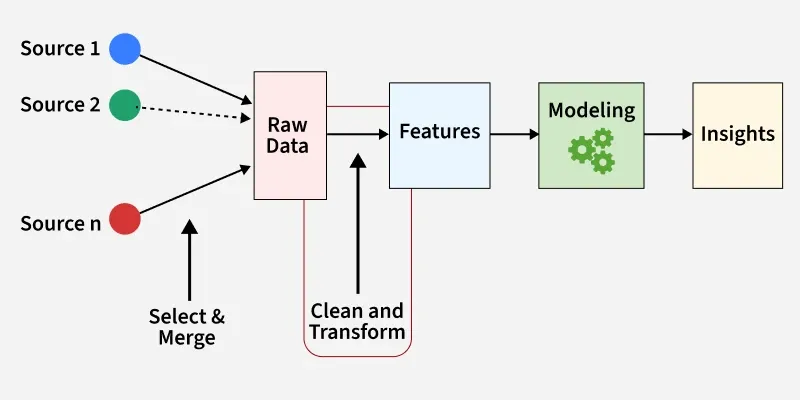

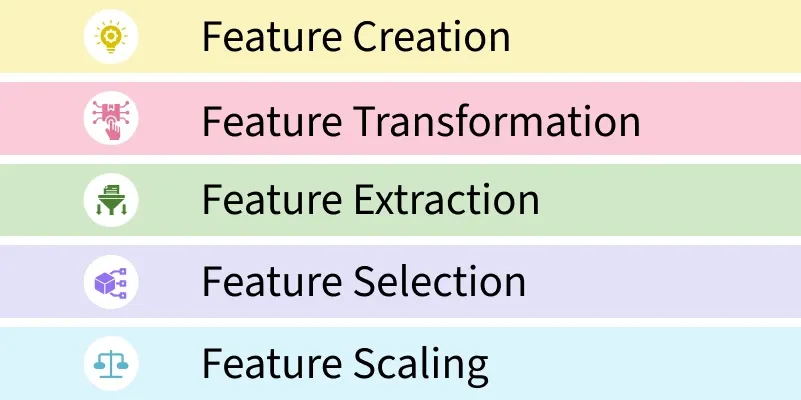

# Flowchart

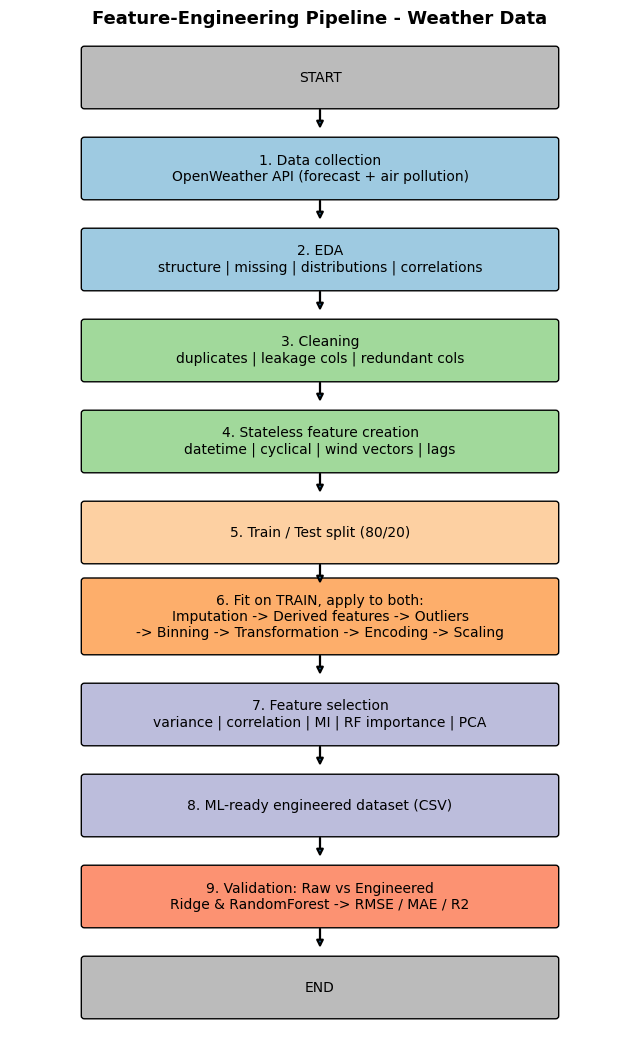

# 7. Python Code


### 7.0 Setup

In [ ]:
# !pip install -q requests pandas numpy matplotlib seaborn scikit-learn scipy
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, PowerTransformer,
                                   KBinsDiscretizer, OneHotEncoder, PolynomialFeatures)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.0)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup complete")

Setup complete


### 7.1 Data Collection (Web Scraping via OpenWeather API)

We call two OpenWeather endpoints for ~65 cities spread over all continents, climates and hemispheres:

| Endpoint | What we get |
|---|---|
| `/data/2.5/forecast` | 5-day / 3-hour forecast: temperature, pressure, humidity, clouds, wind, visibility, rain/snow, day/night flag, city sunrise/sunset, timezone, population |
| `/data/2.5/air_pollution/forecast` | AQI and pollutant concentrations (CO, NO, NO2, O3, SO2, PM2.5, PM10, NH3) |

The scraper is written to a standalone file `weather_scraper.py` (below) and imported.
The API key is read from the environment variable `OPENWEATHER_API_KEY` (recommended); the key from the assignment is used as default.

In [ ]:
%%writefile weather_scraper.py
"""Weather data scraper for OpenWeather APIs (forecast + air pollution)."""
import time
import requests
import pandas as pd

BASE = "https://api.openweathermap.org/data/2.5"

# (city, country, latitude, longitude)
CITIES = [
    ("Pune", "IN", 18.52, 73.86), ("Mumbai", "IN", 19.08, 72.88), ("Delhi", "IN", 28.61, 77.21),
    ("Bengaluru", "IN", 12.97, 77.59), ("Chennai", "IN", 13.08, 80.27), ("Kolkata", "IN", 22.57, 88.36),
    ("Hyderabad", "IN", 17.39, 78.49), ("Ahmedabad", "IN", 23.02, 72.57), ("Jaipur", "IN", 26.91, 75.79),
    ("Lucknow", "IN", 26.85, 80.95), ("Shimla", "IN", 31.10, 77.17), ("Leh", "IN", 34.15, 77.58),
    ("London", "GB", 51.51, -0.13), ("Paris", "FR", 48.86, 2.35), ("Berlin", "DE", 52.52, 13.41),
    ("Madrid", "ES", 40.42, -3.70), ("Rome", "IT", 41.90, 12.50), ("Moscow", "RU", 55.76, 37.62),
    ("Oslo", "NO", 59.91, 10.75), ("Reykjavik", "IS", 64.15, -21.94), ("Stockholm", "SE", 59.33, 18.07),
    ("Istanbul", "TR", 41.01, 28.98), ("Cairo", "EG", 30.04, 31.24), ("Lagos", "NG", 6.52, 3.38),
    ("Nairobi", "KE", -1.29, 36.82), ("Johannesburg", "ZA", -26.20, 28.05), ("Cape Town", "ZA", -33.92, 18.42),
    ("Addis Ababa", "ET", 9.03, 38.74), ("Dubai", "AE", 25.20, 55.27), ("Riyadh", "SA", 24.71, 46.68),
    ("Tehran", "IR", 35.69, 51.39), ("Karachi", "PK", 24.86, 67.01), ("Dhaka", "BD", 23.81, 90.41),
    ("Kathmandu", "NP", 27.72, 85.32), ("Colombo", "LK", 6.93, 79.86), ("Bangkok", "TH", 13.76, 100.50),
    ("Singapore", "SG", 1.35, 103.82), ("Jakarta", "ID", -6.21, 106.85), ("Manila", "PH", 14.60, 120.98),
    ("Hanoi", "VN", 21.03, 105.85), ("Beijing", "CN", 39.90, 116.41), ("Shanghai", "CN", 31.23, 121.47),
    ("Hong Kong", "HK", 22.32, 114.17), ("Seoul", "KR", 37.57, 126.98), ("Tokyo", "JP", 35.68, 139.69),
    ("Sapporo", "JP", 43.06, 141.35), ("Ulaanbaatar", "MN", 47.89, 106.91), ("Sydney", "AU", -33.87, 151.21),
    ("Melbourne", "AU", -37.81, 144.96), ("Perth", "AU", -31.95, 115.86), ("Auckland", "NZ", -36.85, 174.76),
    ("New York", "US", 40.71, -74.01), ("Los Angeles", "US", 34.05, -118.24), ("Chicago", "US", 41.88, -87.63),
    ("Houston", "US", 29.76, -95.37), ("Anchorage", "US", 61.22, -149.90), ("Honolulu", "US", 21.31, -157.86),
    ("Toronto", "CA", 43.65, -79.38), ("Vancouver", "CA", 49.28, -123.12), ("Mexico City", "MX", 19.43, -99.13),
    ("Havana", "CU", 23.11, -82.37), ("Bogota", "CO", 4.71, -74.07), ("Lima", "PE", -12.05, -77.04),
    ("Sao Paulo", "BR", -23.55, -46.63), ("Buenos Aires", "AR", -34.60, -58.38), ("Santiago", "CL", -33.45, -70.67),
]


def _get(url, params, retries=3, pause=1.2):
    """GET request with retry/back-off. Returns JSON dict or None."""
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=15)
            if r.status_code == 200:
                return r.json()
            if r.status_code == 401:
                raise PermissionError("401 Unauthorized - invalid or not-yet-activated API key "
                                      "(new OpenWeather keys can take a couple of hours to activate).")
            if r.status_code == 429:          # rate limit
                time.sleep(5 * (attempt + 1))
        except requests.RequestException:
            time.sleep(pause * (attempt + 1))
    return None


def fetch_city(api_key, name, country, lat, lon):
    """Return a list of row-dicts (one per 3-hour forecast slot) for one city."""
    fc = _get(f"{BASE}/forecast", dict(lat=lat, lon=lon, appid=api_key, units="metric"))
    if fc is None:
        return []
    air = _get(f"{BASE}/air_pollution/forecast", dict(lat=lat, lon=lon, appid=api_key))
    air_map = {}
    if air:
        for item in air.get("list", []):
            air_map[item["dt"]] = {"aqi": item["main"]["aqi"], **item["components"]}

    city = fc.get("city", {})
    rows = []
    for it in fc.get("list", []):
        m, w, wind = it.get("main", {}), it.get("weather", [{}])[0], it.get("wind", {})
        row = dict(
            city=name, country=country, lat=lat, lon=lon, dt=it["dt"], dt_txt=it.get("dt_txt"),
            temp=m.get("temp"), feels_like=m.get("feels_like"), temp_min=m.get("temp_min"),
            temp_max=m.get("temp_max"), pressure=m.get("pressure"), sea_level=m.get("sea_level"),
            grnd_level=m.get("grnd_level"), humidity=m.get("humidity"),
            weather_id=w.get("id"), weather_main=w.get("main"), weather_description=w.get("description"),
            clouds=it.get("clouds", {}).get("all"), wind_speed=wind.get("speed"), wind_deg=wind.get("deg"),
            wind_gust=wind.get("gust"), visibility=it.get("visibility"), precip_prob=it.get("pop"),
            rain_3h=it.get("rain", {}).get("3h"), snow_3h=it.get("snow", {}).get("3h"),
            pod=it.get("sys", {}).get("pod"), tz_offset=city.get("timezone"),
            sunrise=city.get("sunrise"), sunset=city.get("sunset"), city_population=city.get("population"),
        )
        row.update(air_map.get(it["dt"], {}))
        rows.append(row)
    return rows


def collect_weather_data(api_key, cities=CITIES, sleep=1.1, save_path="weather_raw.csv"):
    """Scrape all cities and return a single DataFrame (also saved to CSV)."""
    all_rows, failures = [], 0
    for i, (name, country, lat, lon) in enumerate(cities, 1):
        rows = fetch_city(api_key, name, country, lat, lon)
        if rows:
            all_rows.extend(rows)
            failures = 0
        else:
            failures += 1
            if len(all_rows) == 0 and failures >= 3:
                raise RuntimeError("API unreachable or key rejected for the first 3 cities.")
        print(f"[{i:02d}/{len(cities)}] {name:<14} rows so far: {len(all_rows)}")
        time.sleep(sleep)               # stay inside the free-tier rate limit (60 calls/min)
    df = pd.DataFrame(all_rows)
    if save_path:
        df.to_csv(save_path, index=False)
    return df

Writing weather_scraper.py


In [ ]:
from weather_scraper import collect_weather_data, CITIES

API_KEY = os.getenv("OPENWEATHER_API_KEY", "4b87cb6da831c5204f27c6bd2e83c9a9")
RAW_PATH = "weather_raw.csv"

# --- Offline fallback so the notebook always runs (only used if the live API is unreachable) ---
def make_synthetic_weather(cities, seed=RANDOM_STATE):
    """Synthetic data with the SAME schema as the OpenWeather scrape (physically plausible)."""
    rng = np.random.default_rng(seed)
    start = pd.Timestamp("2026-10-19 12:00", tz="UTC")
    midnight = int(pd.Timestamp("2026-10-19", tz="UTC").timestamp())
    rows = []
    for name, country, lat, lon in cities:
        tz = int(round(lon / 15)) * 3600
        base = 31 - 0.55 * abs(lat) + rng.normal(0, 2.5)
        base_hum, p_off = rng.uniform(40, 85), rng.normal(0, 3)
        daylen = 12 - 1.2 * np.sign(lat) * min(abs(lat), 60) / 60
        sunrise = midnight + int((12 - daylen / 2) * 3600) - tz
        sunset = sunrise + int(daylen * 3600)
        pol = rng.uniform(0.3, 2.5)
        for k in range(40):
            ts = start + pd.Timedelta(hours=3 * k)
            solar = (ts.hour + ts.minute / 60 + lon / 15) % 24
            diurnal = 5.5 * np.sin(2 * np.pi * (solar - 9) / 24)
            temp = base + diurnal + rng.normal(0, 1.3)
            hum = float(np.clip(base_hum - 1.6 * diurnal + rng.normal(0, 6), 8, 100))
            pres = 1013 + p_off + rng.normal(0, 5)
            clouds = float(np.clip(rng.normal(50, 38), 0, 100))
            ws = rng.gamma(2.0, 1.7) * (4 if rng.random() < 0.01 else 1)
            gust = ws * rng.uniform(1.2, 2.3) if rng.random() < 0.55 else np.nan
            vis = 10000 if rng.random() < 0.8 else rng.integers(500, 9000)
            vis = vis if rng.random() > 0.02 else np.nan
            pp = float(np.clip((clouds / 100) * rng.uniform(0, 1.1), 0, 1))
            rain = rng.gamma(1.3, 1.6) if (rng.random() < pp * 0.35 and temp > 1) else np.nan
            snow = rng.gamma(1.1, 0.8) if (rng.random() < pp * 0.4 and temp <= 1) else np.nan
            main = ("Snow" if pd.notna(snow) else "Rain" if pd.notna(rain)
                    else "Clouds" if clouds > 60 else "Clear" if clouds < 25
                    else rng.choice(["Clouds", "Mist", "Haze"], p=[.75, .1, .15]))
            comp = {c: float(rng.lognormal(m, 0.8) * pol) for c, m in
                    dict(co=5.6, no=-0.5, no2=1.5, o3=4.2, so2=0.9, pm2_5=2.1, pm10=2.7, nh3=0.6).items()}
            aqi = int(np.digitize(comp["pm2_5"], [10, 25, 50, 75]) + 1)
            if rng.random() < 0.015:
                comp["pm10"] = np.nan
            dt = int(ts.timestamp())
            rows.append(dict(
                city=name, country=country, lat=lat, lon=lon, dt=dt, dt_txt=ts.strftime("%Y-%m-%d %H:%M:%S"),
                temp=temp, feels_like=temp + rng.normal(0, 1.5), temp_min=temp - 0.5, temp_max=temp + 0.5,
                pressure=round(pres), sea_level=round(pres), grnd_level=round(pres - rng.uniform(0, 8)),
                humidity=round(hum), weather_id=800, weather_main=main, weather_description=main.lower(),
                clouds=round(clouds), wind_speed=ws, wind_deg=int(rng.integers(0, 360)), wind_gust=gust,
                visibility=vis, precip_prob=pp, rain_3h=rain, snow_3h=snow,
                pod="d" if sunrise % 86400 <= (dt + tz) % 86400 <= sunset % 86400 or 6 <= solar <= 18 else "n",
                tz_offset=tz, sunrise=sunrise, sunset=sunset,
                city_population=int(rng.integers(100_000, 20_000_000)), aqi=aqi, **comp))
    return pd.DataFrame(rows)

if os.path.exists(RAW_PATH):
    df_raw, DATA_SOURCE = pd.read_csv(RAW_PATH), "cached OpenWeather scrape (weather_raw.csv)"
else:
    try:
        df_raw = collect_weather_data(API_KEY, CITIES, save_path=RAW_PATH)
        DATA_SOURCE = "live OpenWeather API scrape"
        assert len(df_raw) > 0
    except Exception as e:
        print("\n[!] Live API collection failed:", e)
        print("[!] Falling back to synthetic data with identical schema so the notebook can still run.")
        df_raw = make_synthetic_weather(CITIES)
        df_raw.to_csv("weather_raw_synthetic.csv", index=False)
        DATA_SOURCE = "SYNTHETIC fallback (API unreachable)"

print("\nDATA SOURCE :", DATA_SOURCE)
print("Raw shape   :", df_raw.shape)

[01/66] Pune           rows so far: 40
[02/66] Mumbai         rows so far: 80
[03/66] Delhi          rows so far: 120
[04/66] Bengaluru      rows so far: 160
[05/66] Chennai        rows so far: 200
[06/66] Kolkata        rows so far: 240
[07/66] Hyderabad      rows so far: 280
[08/66] Ahmedabad      rows so far: 320
[09/66] Jaipur         rows so far: 360
[10/66] Lucknow        rows so far: 400
[11/66] Shimla         rows so far: 440
[12/66] Leh            rows so far: 480
[13/66] London         rows so far: 520
[14/66] Paris          rows so far: 560
[15/66] Berlin         rows so far: 600
[16/66] Madrid         rows so far: 640
[17/66] Rome           rows so far: 680
[18/66] Moscow         rows so far: 720
[19/66] Oslo           rows so far: 760
[20/66] Reykjavik      rows so far: 800
[21/66] Stockholm      rows so far: 840
[22/66] Istanbul       rows so far: 880
[23/66] Cairo          rows so far: 920
[24/66] Lagos          rows so far: 960
[25/66] Nairobi        rows so far: 1000
[

### 7.2 Exploratory Data Analysis (EDA)
#### 7.2.1 Structure of the dataset

In [ ]:
df_raw.head()

,city,country,lat,lon,dt,dt_txt,temp,feels_like,temp_min,temp_max,pressure,sea_level,grnd_level,humidity,weather_id,weather_main,weather_description,clouds,wind_speed,wind_deg,wind_gust,visibility,precip_prob,rain_3h,snow_3h,pod,tz_offset,sunrise,sunset,city_population,aqi,co,no,no2,o3,so2,pm2_5,pm10,nh3
0,Pune,IN,18.52,73.86,1792530000,2026-10-20 21:00:00,25.23,25.22,25.23,25.23,1013,1013,940,54,801,Clouds,few clouds,22,1.20,10,1.18,10000.0,0.0,NaN,NaN,n,19800,1792544393,1792586297,0,5.0,778.93,0.00,2.39,134.70,11.86,233.98,250.93,1.09
1,Pune,IN,18.52,73.86,1792540800,2026-10-21 00:00:00,25.00,24.99,24.54,25.00,1013,1013,941,55,801,Clouds,few clouds,19,1.59,118,1.82,10000.0,0.0,NaN,NaN,n,19800,1792544393,1792586297,0,5.0,614.13,0.00,2.33,81.97,6.98,146.34,157.64,2.81
2,Pune,IN,18.52,73.86,1792551600,2026-10-21 03:00:00,26.59,26.59,26.59,27.27,1015,1015,943,50,801,Clouds,few clouds,12,2.79,111,4.81,10000.0,0.0,NaN,NaN,d,19800,1792544393,1792586297,0,4.0,443.45,0.22,3.53,61.18,3.70,70.88,78.06,4.83
3,Pune,IN,18.52,73.86,1792562400,2026-10-21 06:00:00,32.93,32.88,32.93,32.93,1015,1015,942,36,801,Clouds,few clouds,18,3.70,100,4.30,10000.0,0.0,NaN,NaN,d,19800,1792544393,1792586297,0,4.0,343.46,0.22,1.73,104.28,3.85,53.61,59.94,4.50
4,Pune,IN,18.52,73.86,1792573200,2026-10-21 09:00:00,33.14,32.17,33.14,33.14,1011,1011,939,30,802,Clouds,scattered clouds,46,2.97,82,3.03,10000.0,0.0,NaN,NaN,d,19800,1792544393,1792586297,0,4.0,336.22,0.13,1.24,133.01,3.87,69.58,75.99,2.96


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2640 entries, 0 to 2639
Data columns (total 39 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   city                 2640 non-null   object 
 1   country              2640 non-null   object 
 2   lat                  2640 non-null   float64
 3   lon                  2640 non-null   float64
 4   dt                   2640 non-null   int64  
 5   dt_txt               2640 non-null   object 
 6   temp                 2640 non-null   float64
 7   feels_like           2640 non-null   float64
 8   temp_min             2640 non-null   float64
 9   temp_max             2640 non-null   float64
 10  pressure             2640 non-null   int64  
 11  sea_level            2640 non-null   int64  
 12  grnd_level           2640 non-null   int64  
 13  humidity             2640 non-null   int64  
 14  weather_id           2640 non-null   int64  
 15  weather_main         2640 non-null   o

In [ ]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lat,2640.0,2.076000e+01,26.58,-3.781000e+01,9.030000e+00,2.478000e+01,4.042000e+01,6.415000e+01
lon,2640.0,3.426000e+01,81.29,-1.578600e+02,-3.700000e+00,5.333000e+01,9.041000e+01,1.747600e+02
dt,2640.0,1.792741e+09,124692.30,1.792530e+09,1.792635e+09,1.792741e+09,1.792846e+09,1.792951e+09
temp,2640.0,1.914000e+01,8.97,-8.560000e+00,1.249000e+01,1.955000e+01,2.677000e+01,3.716000e+01
feels_like,2640.0,1.906000e+01,10.35,-1.327000e+01,1.178000e+01,1.915000e+01,2.685000e+01,4.345000e+01
temp_min,2640.0,1.911000e+01,8.98,-9.820000e+00,1.244000e+01,1.950000e+01,2.675000e+01,3.716000e+01
temp_max,2640.0,1.916000e+01,8.98,-8.560000e+00,1.250000e+01,1.958000e+01,2.682000e+01,3.716000e+01
pressure,2640.0,1.015120e+03,7.59,9.830000e+02,1.011000e+03,1.014000e+03,1.020000e+03,1.039000e+03
sea_level,2640.0,1.015120e+03,7.59,9.830000e+02,1.011000e+03,1.014000e+03,1.020000e+03,1.039000e+03
grnd_level,2640.0,9.669500e+02,82.78,5.920000e+02,9.490000e+02,1.006000e+03,1.012000e+03,1.031000e+03


In [ ]:
print("Duplicate rows       :", df_raw.duplicated().sum())
print("Cities / countries   :", df_raw.city.nunique(), "/", df_raw.country.nunique())
print("Rows per city        :", df_raw.groupby('city').size().unique())
print("\nCategorical columns :", df_raw.select_dtypes(include='object').columns.tolist())
print("Numeric columns      :", df_raw.select_dtypes(include='number').shape[1])

Duplicate rows       : 0
Cities / countries   : 66 / 44
Rows per city        : [40]

Categorical columns : ['city', 'country', 'dt_txt', 'weather_main', 'weather_description', 'pod']
Numeric columns      : 33


#### 7.2.2 Missing values

snow_3h       99.70
rain_3h       78.67
no2           20.00
no            20.00
co            20.00
nh3           20.00
so2           20.00
pm2_5         20.00
aqi           20.00
pm10          20.00
o3            20.00
visibility     0.11


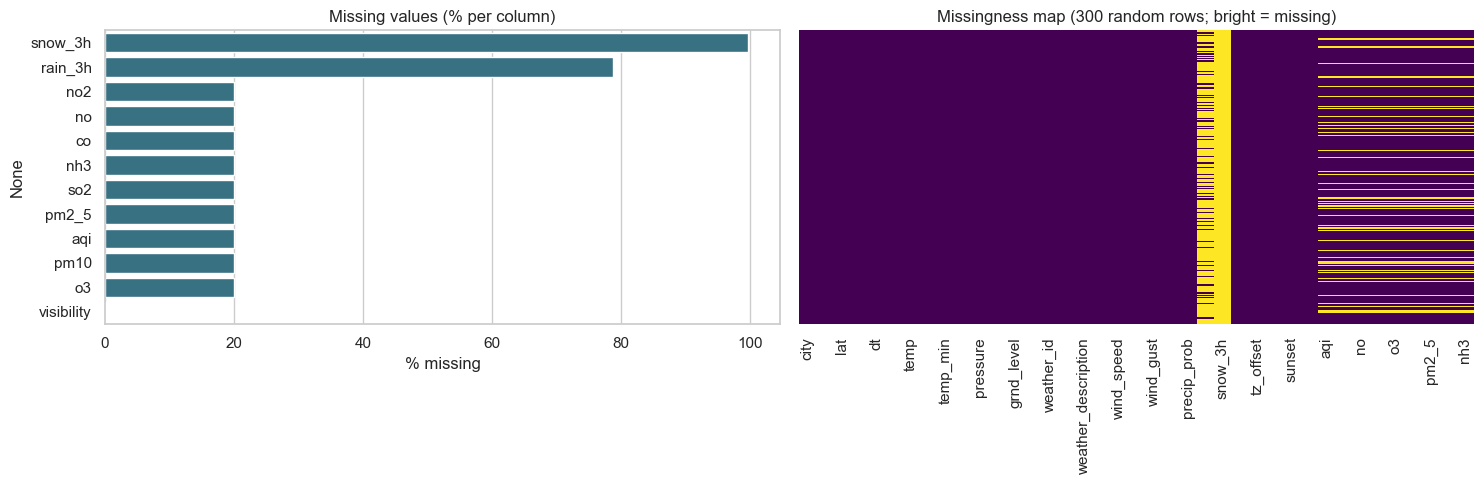

In [ ]:
miss = (df_raw.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(2).to_string() if len(miss) else "No missing values")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
if len(miss):
    sns.barplot(x=miss.values, y=miss.index, ax=ax[0], color="#2a788e")
ax[0].set_title("Missing values (% per column)"); ax[0].set_xlabel("% missing")
sns.heatmap(df_raw.sample(300, random_state=1).isna(), cbar=False, yticklabels=False, ax=ax[1], cmap="viridis")
ax[1].set_title("Missingness map (300 random rows; bright = missing)")
plt.tight_layout(); plt.show()

*Note:* `rain_3h` / `snow_3h` are absent when no precipitation is expected (so NaN really means 0), while `wind_gust`/`visibility`/`pm10` are genuine gaps - they need different imputation strategies.

#### 7.2.3 Univariate analysis

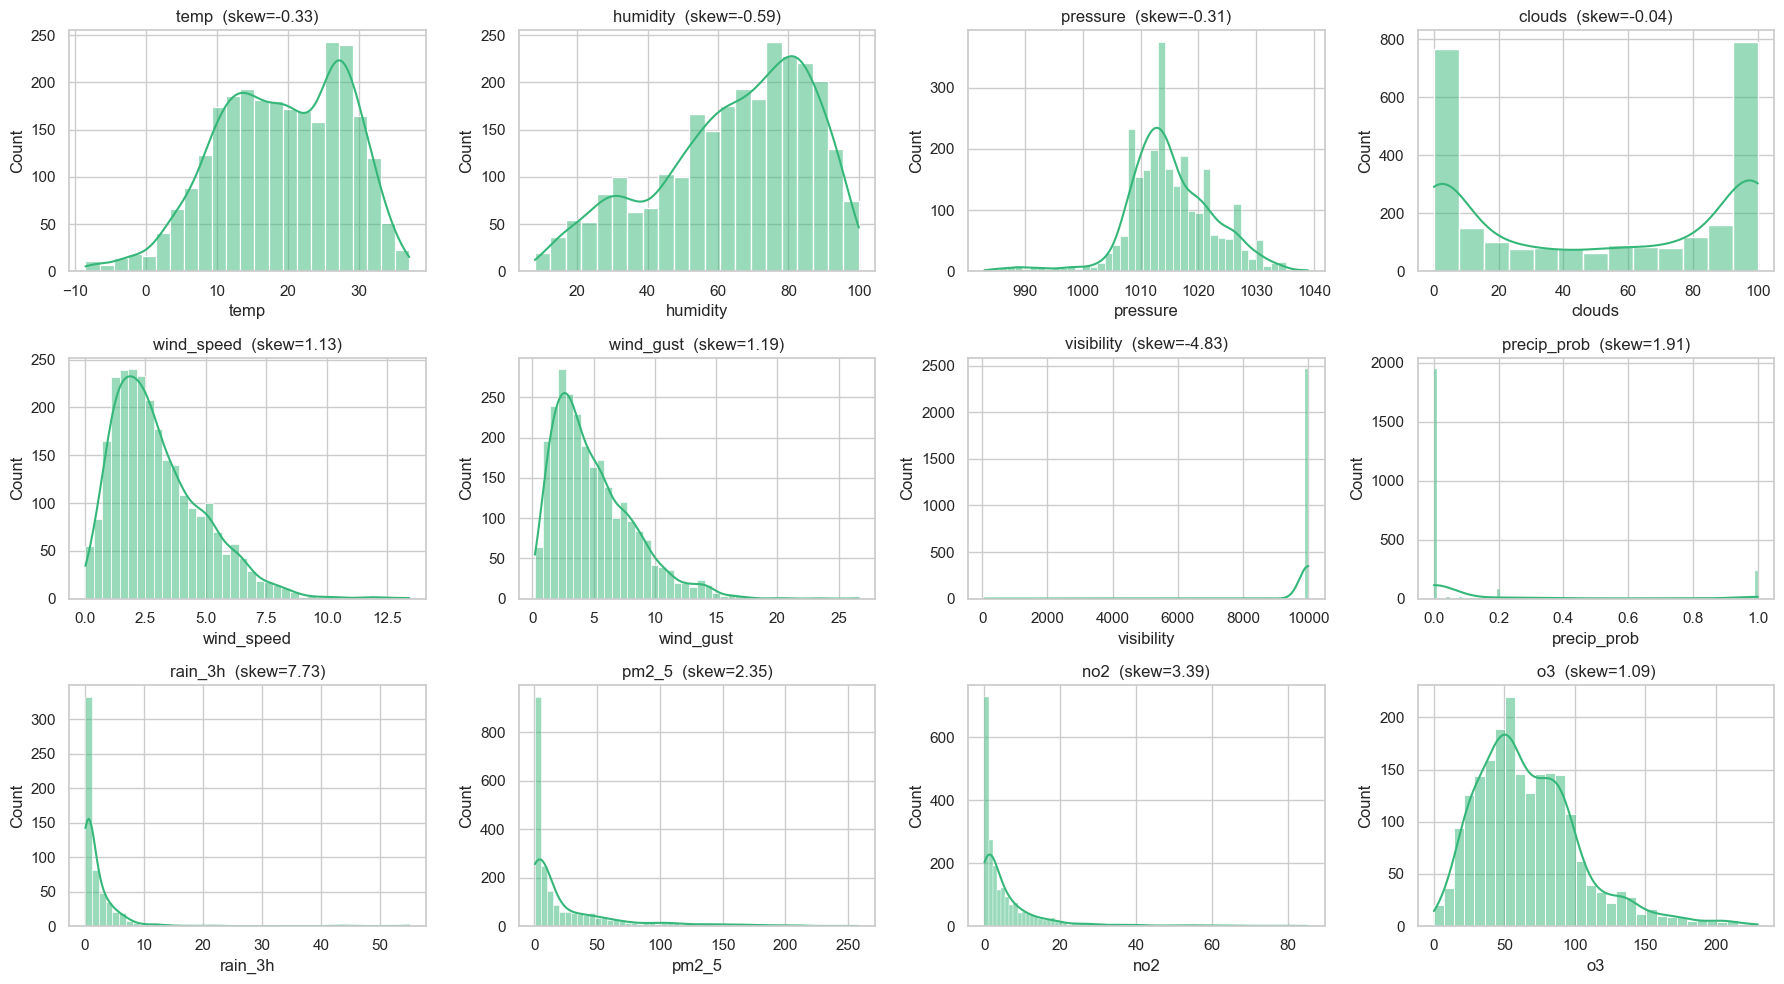

In [ ]:
eda_num = [c for c in ["temp", "humidity", "pressure", "clouds", "wind_speed", "wind_gust", "visibility",
                       "precip_prob", "rain_3h", "pm2_5", "no2", "o3"] if c in df_raw.columns]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), eda_num):
    sns.histplot(df_raw[c].dropna(), kde=True, ax=ax, color="#35b779")
    ax.set_title(f"{c}  (skew={df_raw[c].skew():.2f})")
plt.tight_layout(); plt.show()

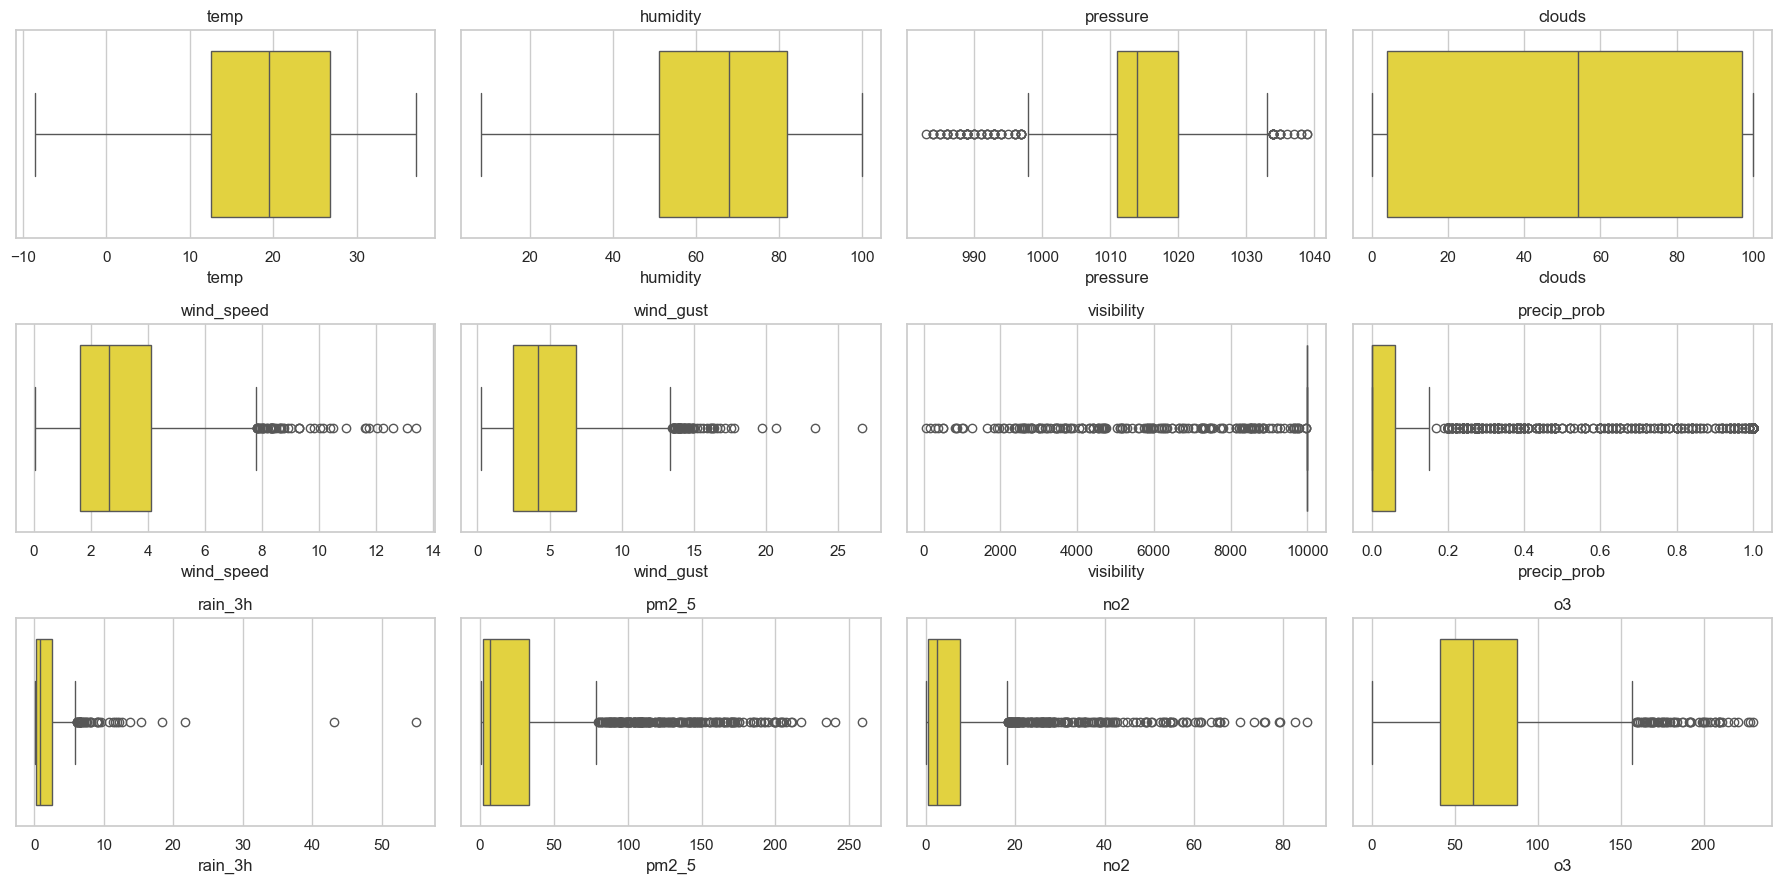

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(18, 9))
for ax, c in zip(axes.ravel(), eda_num):
    sns.boxplot(x=df_raw[c], ax=ax, color="#fde725")
    ax.set_title(c)
plt.tight_layout(); plt.show()

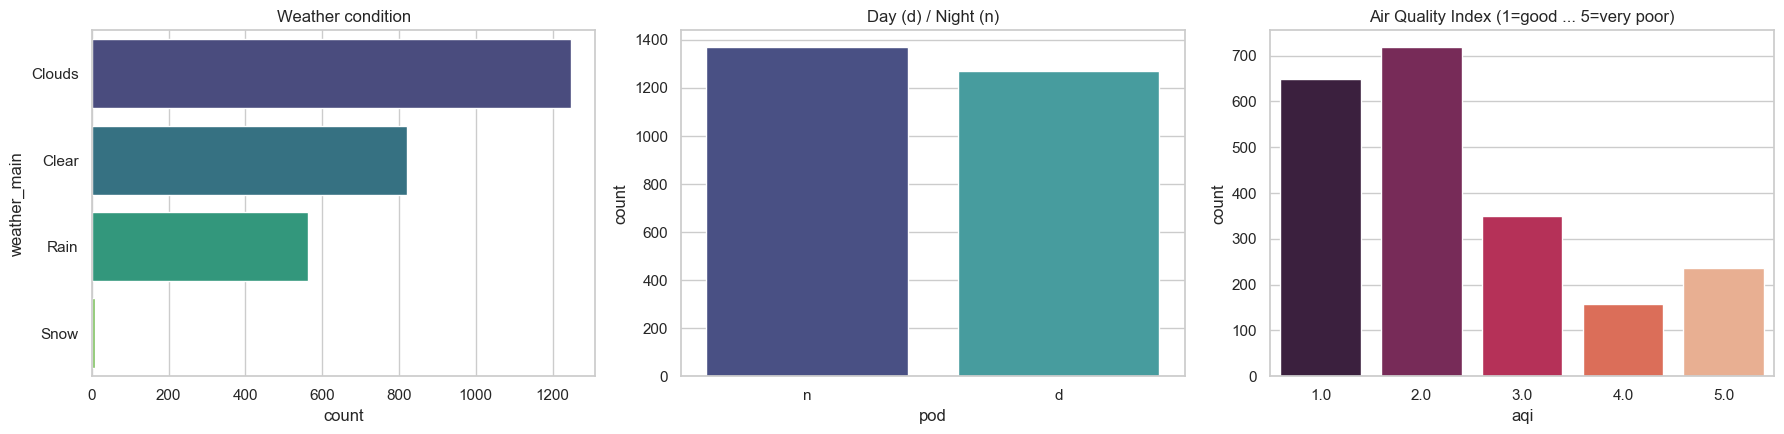

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(y="weather_main", data=df_raw, order=df_raw.weather_main.value_counts().index, ax=ax[0], palette="viridis")
ax[0].set_title("Weather condition")
sns.countplot(x="pod", data=df_raw, ax=ax[1], palette="mako"); ax[1].set_title("Day (d) / Night (n)")
sns.countplot(x="aqi", data=df_raw, ax=ax[2], palette="rocket"); ax[2].set_title("Air Quality Index (1=good ... 5=very poor)")
plt.tight_layout(); plt.show()

#### 7.2.4 Bivariate / multivariate analysis

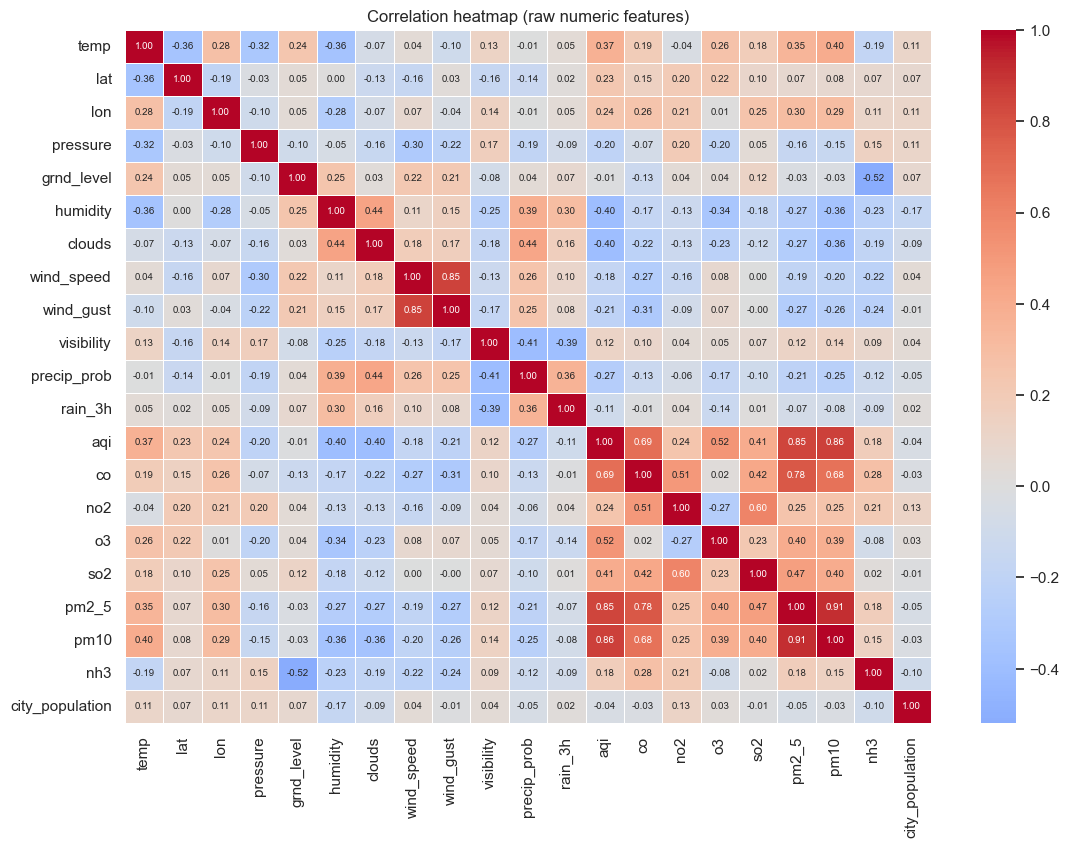

In [ ]:
corr_cols = [c for c in ["temp", "lat", "lon", "pressure", "grnd_level", "humidity", "clouds", "wind_speed",
                         "wind_gust", "visibility", "precip_prob", "rain_3h", "aqi", "co", "no2", "o3",
                         "so2", "pm2_5", "pm10", "nh3", "city_population"] if c in df_raw.columns]
plt.figure(figsize=(13, 9))
sns.heatmap(df_raw[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.4, annot_kws={"size": 7})
plt.title("Correlation heatmap (raw numeric features)"); plt.show()

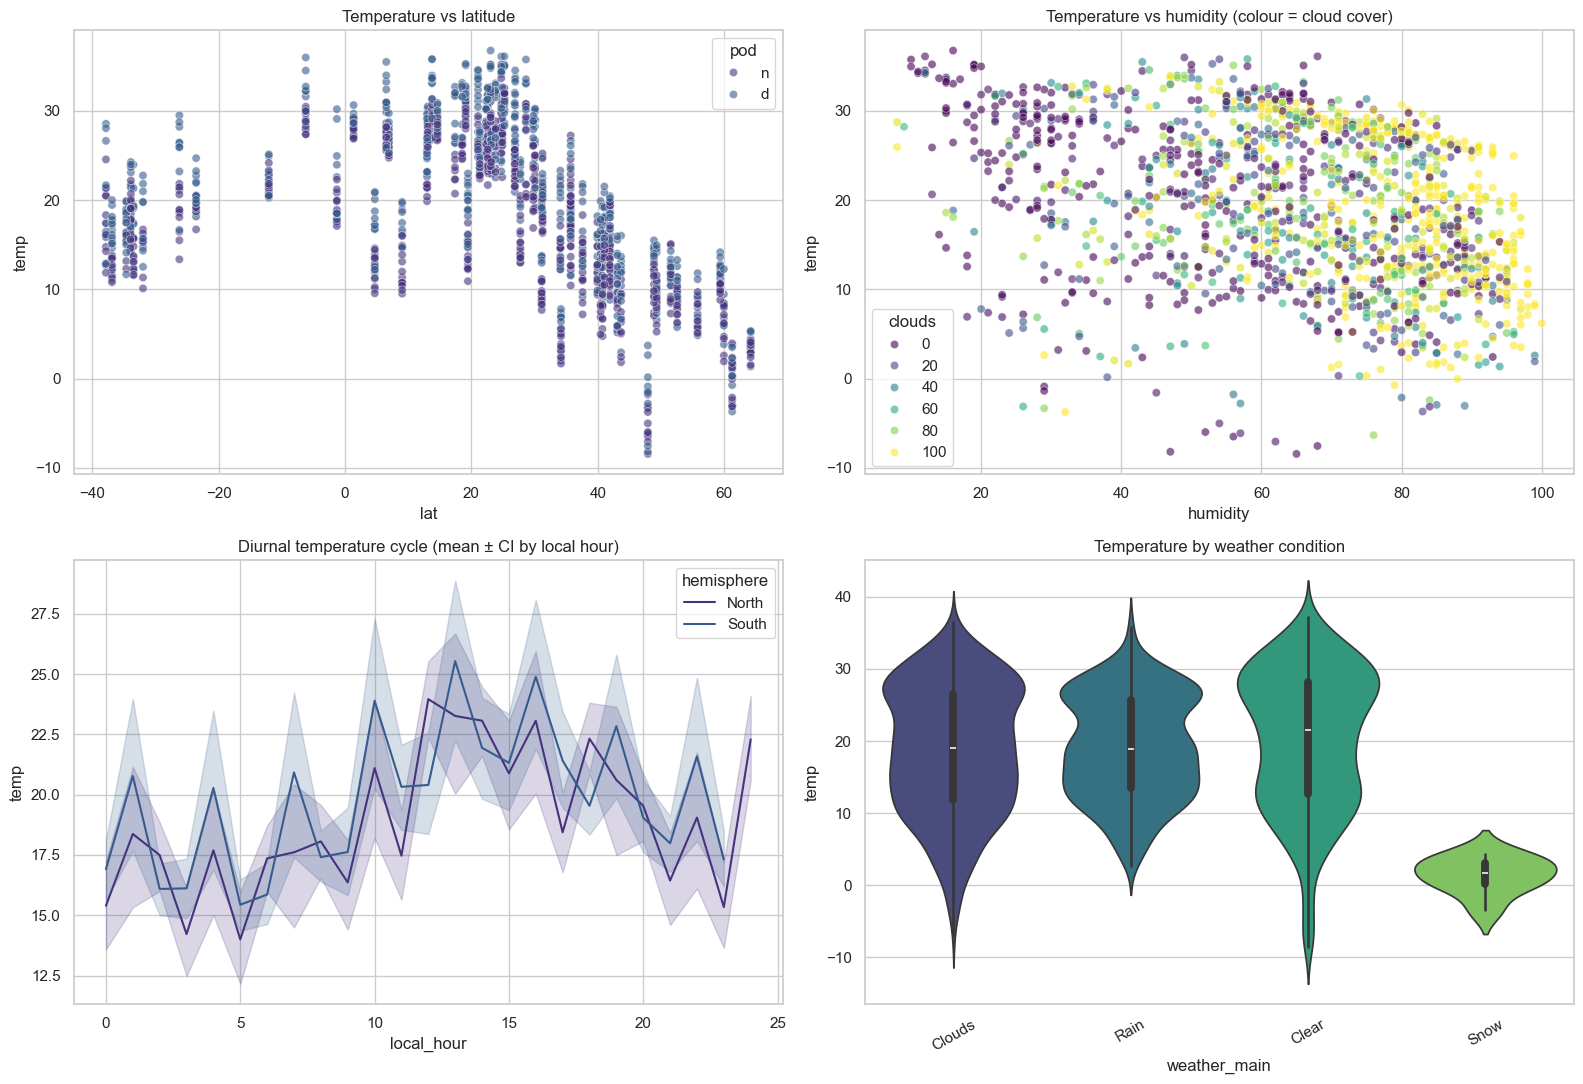

In [ ]:
eda = df_raw.copy()
eda["local_hour"] = ((pd.to_datetime(eda.dt, unit="s").dt.hour + eda.tz_offset / 3600) % 24).round()
eda["hemisphere"] = np.where(eda.lat >= 0, "North", "South")

fig, ax = plt.subplots(2, 2, figsize=(16, 11))
sns.scatterplot(data=eda.sample(min(1500, len(eda)), random_state=1), x="lat", y="temp", hue="pod", alpha=.6, ax=ax[0, 0])
ax[0, 0].set_title("Temperature vs latitude")
sns.scatterplot(data=eda.sample(min(1500, len(eda)), random_state=1), x="humidity", y="temp", hue="clouds", palette="viridis", alpha=.6, ax=ax[0, 1])
ax[0, 1].set_title("Temperature vs humidity (colour = cloud cover)")
sns.lineplot(data=eda, x="local_hour", y="temp", hue="hemisphere", ax=ax[1, 0])
ax[1, 0].set_title("Diurnal temperature cycle (mean ± CI by local hour)")
sns.violinplot(data=eda, x="weather_main", y="temp", ax=ax[1, 1], palette="viridis")
ax[1, 1].set_title("Temperature by weather condition"); ax[1, 1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

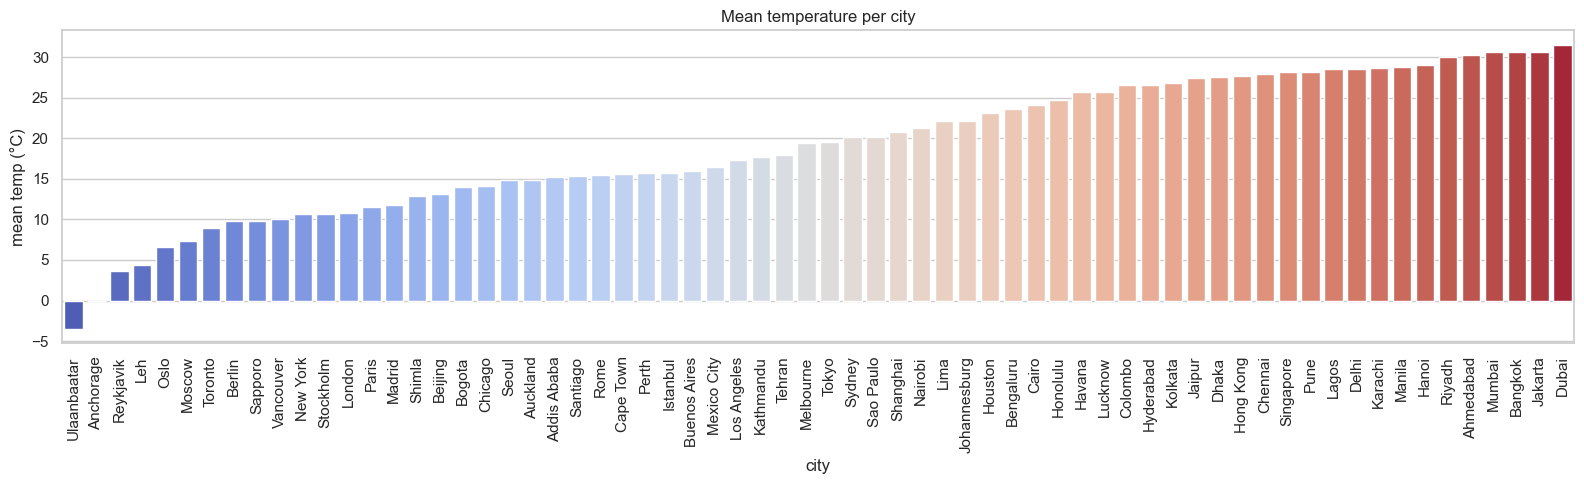

In [ ]:
city_mean = eda.groupby("city")["temp"].mean().sort_values()
plt.figure(figsize=(16, 5))
sns.barplot(x=city_mean.index, y=city_mean.values, palette="coolwarm")
plt.xticks(rotation=90); plt.ylabel("mean temp (°C)"); plt.title("Mean temperature per city"); plt.tight_layout(); plt.show()

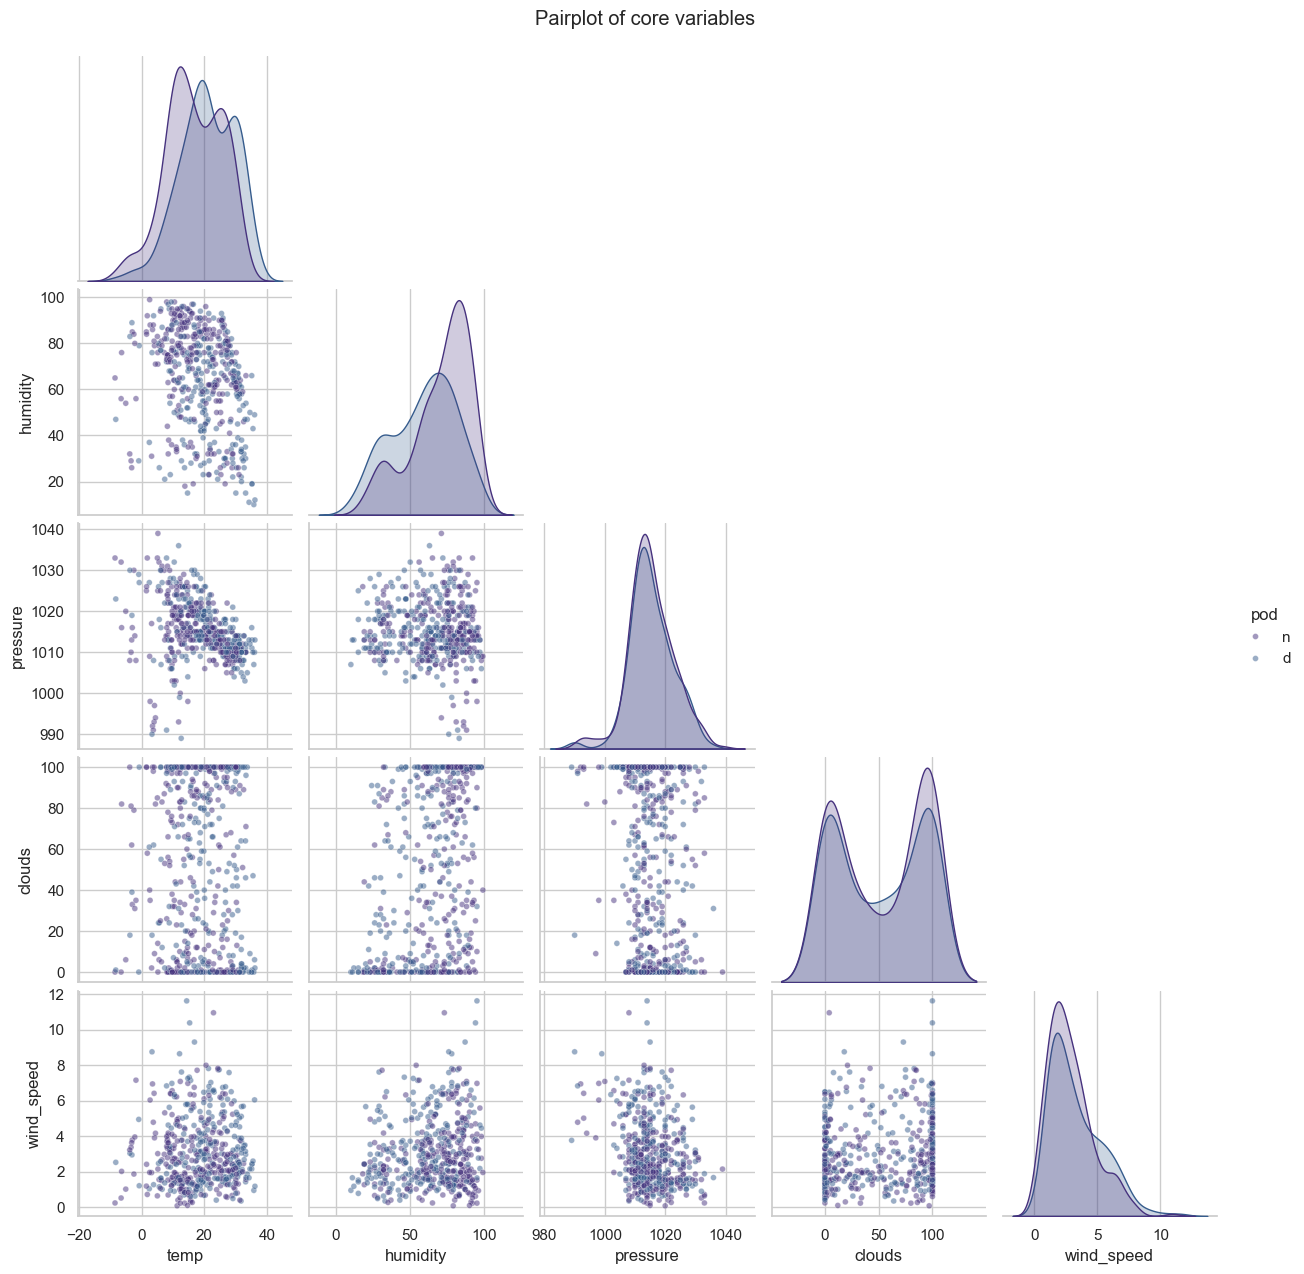

In [ ]:
pp_cols = [c for c in ["temp", "humidity", "pressure", "clouds", "wind_speed"] if c in df_raw.columns]
sns.pairplot(df_raw.sample(min(500, len(df_raw)), random_state=1)[pp_cols + ["pod"]], hue="pod", corner=True, plot_kws=dict(alpha=.5, s=18))
plt.suptitle("Pairplot of core variables", y=1.02); plt.show()

#### 7.2.5 EDA insights
* **Latitude** and **time of day** are the strongest drivers of temperature; humidity is negatively correlated with temperature (warm air → lower relative humidity).
* Temperature follows a **cyclic daily pattern** → raw `hour` is a poor feature; cyclic (sin/cos) and *solar-time* features should work better.
* `wind_speed`, `rain_3h`, and the pollutant columns are **heavily right-skewed with outliers** → need capping + log/Yeo-Johnson transforms.
* `wind_gust`, `visibility`, `pm10` contain real **missing values**; `rain/snow` NaN means "no precipitation".
* `sea_level` is identical to `pressure` (redundant); `feels_like`, `temp_min`, `temp_max` leak the target.
* Categorical variables: `weather_main` (nominal, low cardinality), `country`/`city` (high cardinality), `pod` (binary).

### 7.3 Data Cleaning & Stateless Feature Creation
These transformations use **only the row's own values** (no statistics learned from data), so they can safely be applied before the train/test split.

In [ ]:
TARGET = "temp"

df0 = df_raw.copy()
print("Duplicates removed:", df0.duplicated().sum())
df0 = df0.drop_duplicates().sort_values(["city", "dt"]).reset_index(drop=True)
df0["dt_utc"] = pd.to_datetime(df0["dt"], unit="s", utc=True)

print("sea_level identical to pressure in", round((df0.sea_level == df0.pressure).mean() * 100, 1), "% of rows -> redundant")
DROP_COLS = ["dt_txt", "weather_id", "weather_description",   # text / duplicates of weather_main
             "feels_like", "temp_min", "temp_max",             # target leakage
             "sea_level"]                                      # redundant
df0 = df0.drop(columns=DROP_COLS, errors="ignore")
print("Clean shape:", df0.shape)

Duplicates removed: 0
sea_level identical to pressure in 100.0 % of rows -> redundant
Clean shape: (2640, 33)


#### 7.3.1 Datetime features (extraction + cyclical encoding + solar time)

In [ ]:
df_fe = df0.copy()
dt = df_fe["dt_utc"]
df_fe["hour_utc"] = dt.dt.hour
df_fe["day"] = dt.dt.day
df_fe["dayofweek"] = dt.dt.dayofweek
df_fe["month"] = dt.dt.month
df_fe["is_weekend"] = (df_fe["dayofweek"] >= 5).astype(int)

local_ts = dt + pd.to_timedelta(df_fe["tz_offset"], unit="s")
df_fe["local_hour"] = local_ts.dt.hour + local_ts.dt.minute / 60
df_fe["solar_hour"] = (dt.dt.hour + dt.dt.minute / 60 + df_fe["lon"] / 15) % 24       # true solar time from longitude

# cyclical encoding: hour 23 and hour 0 should be neighbours
for name in ["local_hour", "solar_hour"]:
    df_fe[f"{name}_sin"] = np.sin(2 * np.pi * df_fe[name] / 24)
    df_fe[f"{name}_cos"] = np.cos(2 * np.pi * df_fe[name] / 24)
df_fe["dayofweek_sin"] = np.sin(2 * np.pi * df_fe["dayofweek"] / 7)
df_fe["dayofweek_cos"] = np.cos(2 * np.pi * df_fe["dayofweek"] / 7)

# sun-based features
loc_sec = (df_fe["dt"] + df_fe["tz_offset"]) % 86400
sunrise_sec = (df_fe["sunrise"] + df_fe["tz_offset"]) % 86400
df_fe["hours_since_sunrise"] = ((loc_sec - sunrise_sec) / 3600) % 24
df_fe["daylight_hours"] = ((df_fe["sunset"] - df_fe["sunrise"]) / 3600) % 24

# time-of-day bucket (binning of hour; nominal -> one-hot later)
df_fe["day_part"] = pd.cut(df_fe["local_hour"], [-0.01, 5, 11, 17, 21, 24],
                           labels=["Night", "Morning", "Afternoon", "Evening", "Late_Night"]).astype(str)

#### 7.3.2 Geographic, wind-vector, atmospheric, flag and lag features

In [ ]:
# --- geography ---
df_fe["abs_lat"] = df_fe["lat"].abs()
df_fe["hemisphere_north"] = (df_fe["lat"] >= 0).astype(int)
df_fe["dist_equator_km"] = df_fe["abs_lat"] * 111.0

# --- wind: convert (speed, direction) into vector components + cyclic direction ---
rad = np.deg2rad(df_fe["wind_deg"])
df_fe["wind_u"] = -df_fe["wind_speed"] * np.sin(rad)
df_fe["wind_v"] = -df_fe["wind_speed"] * np.cos(rad)
df_fe["wind_dir_sin"], df_fe["wind_dir_cos"] = np.sin(rad), np.cos(rad)
df_fe["wind_power"] = df_fe["wind_speed"] ** 3                  # kinetic-energy flux ∝ v^3

# --- atmosphere ---
df_fe["pressure_dev"] = df_fe["pressure"] - 1013.25
df_fe["pressure_grnd_diff"] = df_fe["pressure"] - df_fe["grnd_level"]       # proxy for station altitude
df_fe["humidity_x_clouds"] = df_fe["humidity"] * df_fe["clouds"] / 100      # interaction: moisture & cloud
df_fe["clear_sky"] = 100 - df_fe["clouds"]

# --- missing-value indicator flags (missingness itself can be informative) ---
df_fe["has_gust"] = df_fe["wind_gust"].notna().astype(int)
df_fe["vis_missing"] = df_fe["visibility"].isna().astype(int)
df_fe["is_raining"] = (df_fe["rain_3h"].fillna(0) > 0).astype(int)
df_fe["is_snowing"] = (df_fe["snow_3h"].fillna(0) > 0).astype(int)
df_fe["is_day"] = df_fe["pod"].map({"d": 1, "n": 0}).astype(int)             # binary encoding

# --- temporal lag / rolling features per city (only PAST values of non-target columns) ---
g = df_fe.groupby("city")
for col in ["humidity", "pressure", "clouds"]:
    df_fe[f"{col}_lag1"] = g[col].shift(1)
    df_fe[f"{col}_lag1"] = df_fe.groupby("city")[f"{col}_lag1"].bfill()
    df_fe[f"{col}_change"] = df_fe[col] - df_fe[f"{col}_lag1"]
    df_fe[f"{col}_roll3"] = df_fe.groupby("city")[col].transform(lambda s: s.rolling(3, min_periods=1).mean())

print("Shape after stateless feature creation:", df_fe.shape)
df_fe[["city", "dt_utc", "local_hour", "solar_hour", "hours_since_sunrise", "day_part", "wind_u", "wind_v",
       "humidity_x_clouds", "humidity_change"]].head()

Shape after stateless feature creation: (2640, 75)


,city,dt_utc,local_hour,solar_hour,hours_since_sunrise,day_part,wind_u,wind_v,humidity_x_clouds,humidity_change
0,Addis Ababa,2026-10-20 21:00:00+00:00,0.0,23.582667,17.785,Night,-0.899368,0.363368,23.04,0.0
1,Addis Ababa,2026-10-21 00:00:00+00:00,3.0,2.582667,20.785,Night,-1.166976,-0.447960,20.16,0.0
2,Addis Ababa,2026-10-21 03:00:00+00:00,6.0,5.582667,23.785,Morning,-1.249239,-0.043624,10.92,4.0
3,Addis Ababa,2026-10-21 06:00:00+00:00,9.0,8.582667,2.785,Morning,-1.871114,-0.953380,3.68,-6.0
4,Addis Ababa,2026-10-21 09:00:00+00:00,12.0,11.582667,5.785,Afternoon,-2.615491,-1.275660,9.36,-7.0


### 7.4 Train / Test Split
All *stateful* transformations (imputers, caps, encoders, scalers, etc.) are **fitted on the training set only** and then applied to the test set → no data leakage.

In [ ]:
train_df, test_df = train_test_split(df_fe, test_size=0.2, random_state=RANDOM_STATE)
train_df, test_df = train_df.copy(), test_df.copy()
print("Train:", train_df.shape, " Test:", test_df.shape)

Train: (2112, 75)  Test: (528, 75)


### 7.5 Missing-Value Imputation
**Strategy**
1. `rain_3h`, `snow_3h`: NaN ≙ no precipitation → fill **0** (domain knowledge; indicator flags already created).
2. Other numeric gaps: compare **mean, median, city-median, KNN and Iterative (MICE-style)** by artificially masking 15 % of known `wind_gust` values and measuring RMSE; the best method is then applied.

Columns with NaN to impute: ['visibility', 'aqi', 'co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10', 'nh3']
Imputation block          : ['visibility', 'aqi', 'co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10', 'nh3', 'lat', 'abs_lat', 'pressure', 'grnd_level', 'humidity', 'clouds', 'wind_speed', 'precip_prob']


,RMSE
knn,1.5185
city_median,1.5539
iterative,1.7566
mean,2.0053
median,2.0430


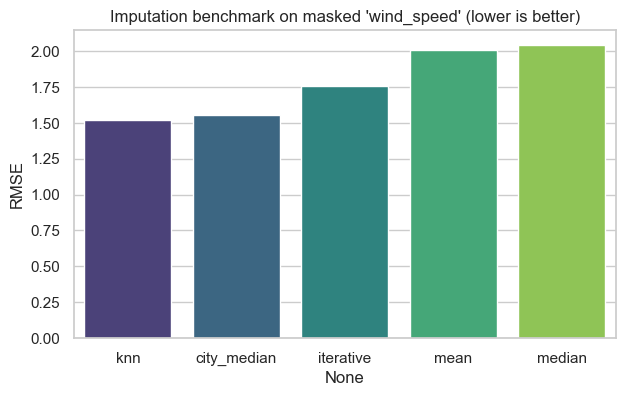

Best imputer -> knn


In [ ]:
for d in (train_df, test_df):
    d[["rain_3h", "snow_3h"]] = d[["rain_3h", "snow_3h"]].fillna(0)

anchors = [c for c in ["lat", "abs_lat", "pressure", "grnd_level", "humidity", "clouds", "wind_speed", "precip_prob"] if c in train_df]
num_candidates = ["wind_gust", "visibility", "aqi", "co", "no", "no2", "o3", "so2", "pm2_5", "pm10", "nh3", "city_population"]
nan_cols = [c for c in num_candidates if c in train_df and train_df[c].isna().any()]
block = list(dict.fromkeys(nan_cols + anchors))
print("Columns with NaN to impute:", nan_cols)
print("Imputation block          :", block)

def impute_block(method, Xtr, Xte):
    """Fit imputer on Xtr, return (imputed Xtr, imputed Xte)."""
    cols = Xtr.columns
    if method in ("mean", "median"):
        imp = SimpleImputer(strategy=method).fit(Xtr)
        f = lambda X: pd.DataFrame(imp.transform(X), columns=cols, index=X.index)
    elif method == "knn":
        sc = StandardScaler().fit(Xtr)
        imp = KNNImputer(n_neighbors=5).fit(sc.transform(Xtr))
        f = lambda X: pd.DataFrame(sc.inverse_transform(imp.transform(sc.transform(X))), columns=cols, index=X.index)
    elif method == "iterative":
        imp = IterativeImputer(max_iter=10, random_state=RANDOM_STATE).fit(Xtr)
        f = lambda X: pd.DataFrame(imp.transform(X), columns=cols, index=X.index)
    elif method == "city_median":
        med, glob = Xtr.groupby(df_fe.loc[Xtr.index, "city"]).median(), Xtr.median()
        def f(X):
            out, cities = X.copy(), df_fe.loc[X.index, "city"]
            for c in cols:
                out[c] = out[c].fillna(cities.map(med[c]).fillna(glob[c]))
            return out
    return f(Xtr), f(Xte)

# --- benchmark by masking known values ---
eval_col = "wind_gust" if ("wind_gust" in block and train_df["wind_gust"].notna().sum() > 100) else "wind_speed"
rng = np.random.default_rng(RANDOM_STATE)
Xb = train_df[block].copy()
known = Xb.index[Xb[eval_col].notna()]
mask_idx = rng.choice(known, size=int(0.15 * len(known)), replace=False)
truth = Xb.loc[mask_idx, eval_col].copy()
Xm = Xb.copy(); Xm.loc[mask_idx, eval_col] = np.nan

methods = ["mean", "median", "city_median", "knn", "iterative"]
scores = {}
for m in methods:
    imp_tr, _ = impute_block(m, Xm, Xm.iloc[:5])
    scores[m] = float(np.sqrt(mean_squared_error(truth, imp_tr.loc[mask_idx, eval_col])))
score_df = pd.Series(scores).sort_values().rename("RMSE").to_frame()
display(score_df.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(x=score_df.index, y=score_df["RMSE"], palette="viridis")
plt.title(f"Imputation benchmark on masked '{eval_col}' (lower is better)"); plt.ylabel("RMSE"); plt.show()
BEST_IMPUTER = score_df.index[0]
print("Best imputer ->", BEST_IMPUTER)

In [ ]:
tr_imp, te_imp = impute_block(BEST_IMPUTER, train_df[block], test_df[block])
train_df[block], test_df[block] = tr_imp, te_imp
print("Remaining NaN (train/test) in imputed block:", int(train_df[block].isna().sum().sum()), "/", int(test_df[block].isna().sum().sum()))
for c in ["aqi"]:
    if c in train_df:
        train_df[c], test_df[c] = train_df[c].round().clip(1, 5), test_df[c].round().clip(1, 5)
print("Total NaN left in the whole train frame:", int(train_df.drop(columns=['dt_utc']).isna().sum().sum()))

Remaining NaN (train/test) in imputed block: 0 / 0
Total NaN left in the whole train frame: 0


### 7.6 Derived (Domain / Interaction / Polynomial / Aggregate) Features
Created **after** imputation so that they never contain NaN.

In [ ]:
poly_cols = ["humidity", "pressure_dev", "clouds"]
poly = PolynomialFeatures(degree=2, include_bias=False).fit(train_df[poly_cols])
poly_names = ["poly_" + n.replace(" ", "_").replace("^", "pow") for n in poly.get_feature_names_out(poly_cols)]
city_stats = train_df.groupby("city")[["humidity", "pressure", "wind_speed"]].mean()      # fitted on TRAIN only
city_stats.columns = ["city_mean_humidity", "city_mean_pressure", "city_mean_wind"]

def add_derived(d):
    d = d.copy()
    # wind gust features
    d["wind_gust_ratio"] = d["wind_gust"] / (d["wind_speed"] + 0.1)
    d["gust_excess"] = d["wind_gust"] - d["wind_speed"]
    # air-quality features
    d["pm_ratio"] = d["pm2_5"] / (d["pm10"] + 1e-6)
    d["particulate_total"] = d["pm2_5"] + d["pm10"]
    d["gas_pollution"] = d["no2"] + d["so2"] + d["o3"]
    # visibility
    d["visibility_km"] = d["visibility"] / 1000
    d["low_visibility"] = (d["visibility"] < 5000).astype(int)
    # polynomial + interaction terms
    P = pd.DataFrame(poly.transform(d[poly_cols]), columns=poly_names, index=d.index).iloc[:, len(poly_cols):]
    d = pd.concat([d, P], axis=1)
    # aggregate (group-level) features & deviation from the city norm
    d = d.join(city_stats, on="city")
    d["humidity_dev_city"] = d["humidity"] - d["city_mean_humidity"]
    d["pressure_dev_city"] = d["pressure"] - d["city_mean_pressure"]
    d["wind_dev_city"] = d["wind_speed"] - d["city_mean_wind"]
    return d

train_df, test_df = add_derived(train_df), add_derived(test_df)
print("Shape:", train_df.shape, "| new poly features:", poly_names[len(poly_cols):] if False else poly_names[len(poly_cols):])

Shape: (2112, 94) | new poly features: ['poly_humiditypow2', 'poly_humidity_pressure_dev', 'poly_humidity_clouds', 'poly_pressure_devpow2', 'poly_pressure_dev_clouds', 'poly_cloudspow2']


### 7.7 Outlier Detection & Treatment
* **Detection:** IQR rule, Z-score (|z|>3), box-plots, and multivariate **Isolation Forest**.
* **Treatment:** winsorization (cap at 1st/99th percentile learned from train), plus new features that *keep* the information (`n_outlier_flags`, `anomaly_score`, `is_anomaly`).

In [ ]:
out_cols = [c for c in ["wind_speed", "wind_gust", "wind_power", "rain_3h", "visibility", "co", "no", "no2", "o3", "so2",
                        "pm2_5", "pm10", "nh3", "wind_gust_ratio", "gust_excess", "pm_ratio", "particulate_total",
                        "gas_pollution", "pressure", "humidity", "pressure_change", "humidity_change"] if c in train_df]

def outlier_summary(d, cols):
    rows = []
    for c in cols:
        x = d[c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append(dict(feature=c, skew=x.skew(), iqr_outliers=int(((x < lo) | (x > hi)).sum()),
                         pct_iqr=100 * ((x < lo) | (x > hi)).mean(), zscore_outliers=int((np.abs(stats.zscore(x)) > 3).sum())))
    return pd.DataFrame(rows).set_index("feature").round(2)

display(outlier_summary(train_df, out_cols))

,skew,iqr_outliers,pct_iqr,zscore_outliers
feature,,,,
wind_speed,1.14,36,1.70,18
wind_gust,1.22,52,2.46,18
wind_power,7.07,234,11.08,30
rain_3h,15.19,441,20.88,32
visibility,-4.93,144,6.82,67
co,2.06,84,3.98,30
no,7.84,334,15.81,41
no2,3.21,177,8.38,57
o3,0.96,49,2.32,25


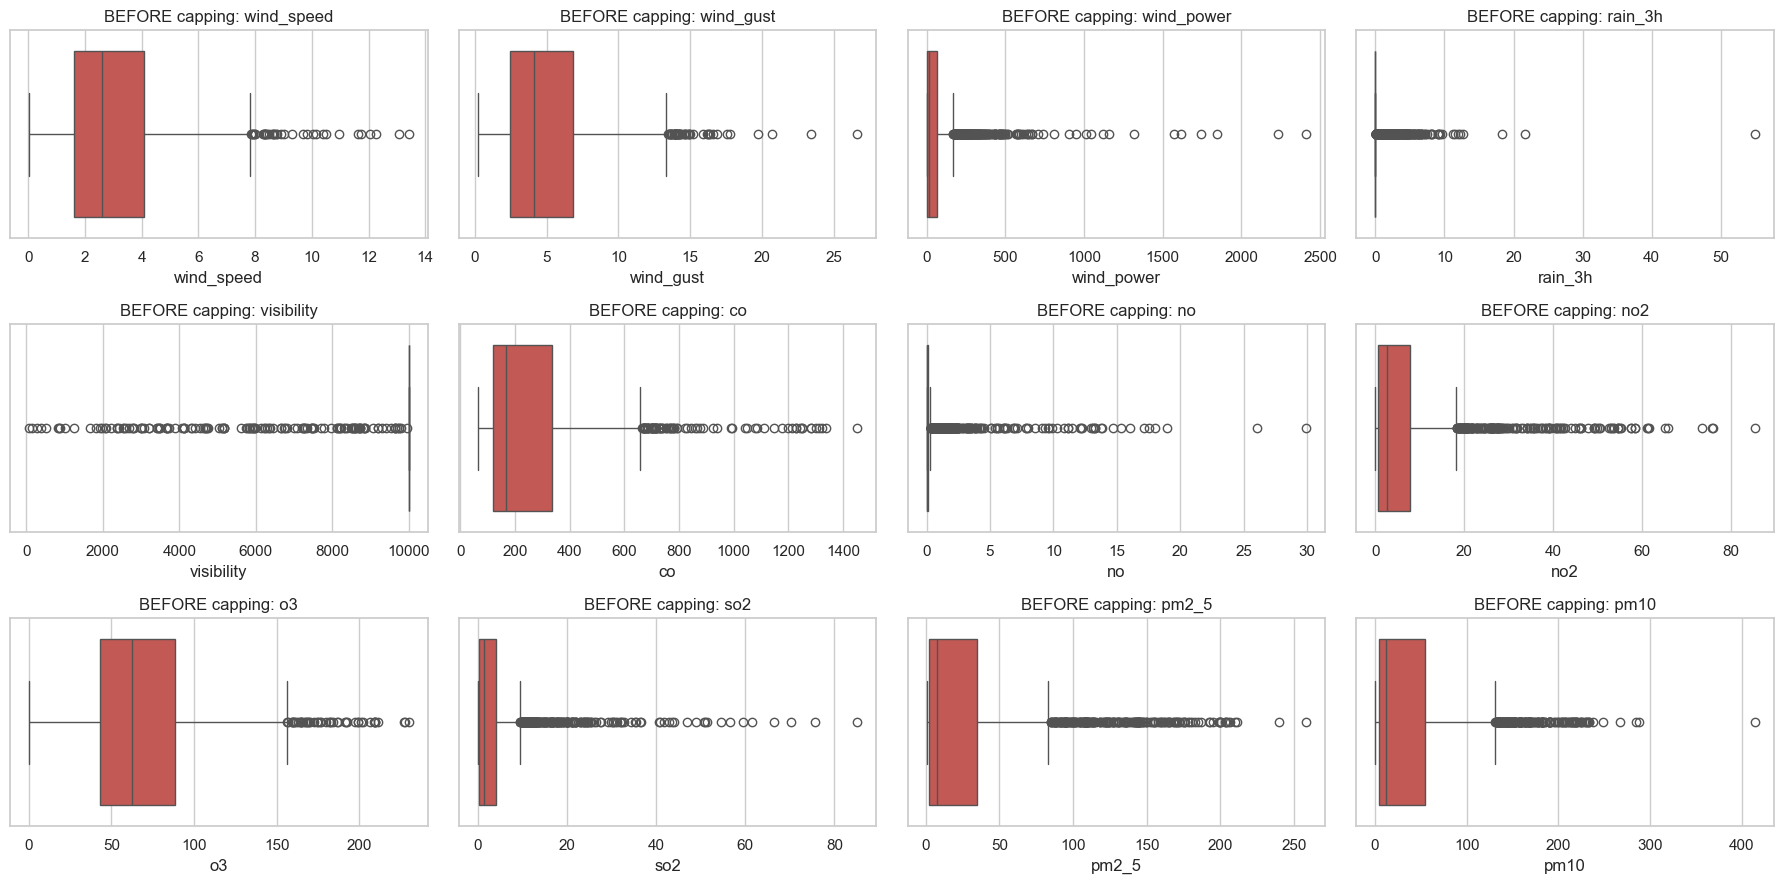

In [ ]:
show = out_cols[:12]
fig, axes = plt.subplots(3, 4, figsize=(18, 9))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(x=train_df[c], ax=ax, color="#d44842"); ax.set_title(f"BEFORE capping: {c}")
plt.tight_layout(); plt.show()

Anomalies flagged  train/test: 43 / 17


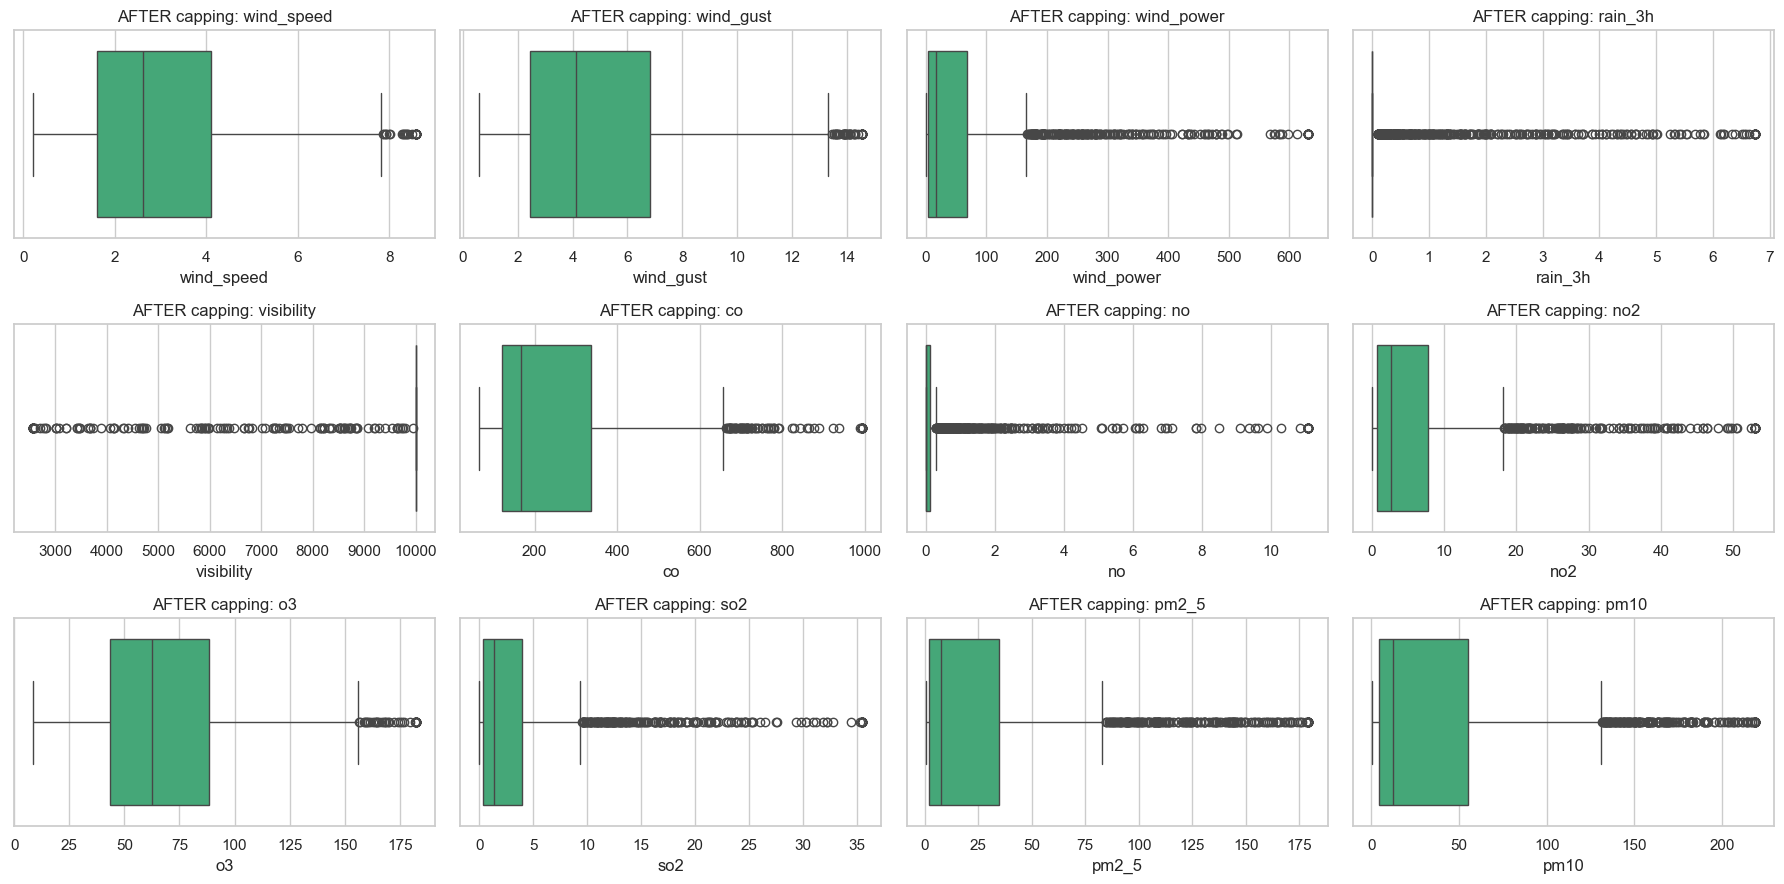

In [ ]:
# IQR fences (train) -> row-level count of outlying features; Isolation Forest -> multivariate anomaly score
fences = {}
for c in out_cols:
    q1, q3 = train_df[c].quantile([.25, .75]); iqr = q3 - q1
    if iqr > 0:
        fences[c] = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=RANDOM_STATE).fit(train_df[out_cols])

def add_outlier_features(d):
    d = d.copy()
    d["n_outlier_flags"] = sum(((d[c] < lo) | (d[c] > hi)).astype(int) for c, (lo, hi) in fences.items())
    d["anomaly_score"] = -iso.score_samples(d[out_cols])
    d["is_anomaly"] = (iso.predict(d[out_cols]) == -1).astype(int)
    return d

train_df, test_df = add_outlier_features(train_df), add_outlier_features(test_df)
print("Anomalies flagged  train/test:", train_df.is_anomaly.sum(), "/", test_df.is_anomaly.sum())

# winsorization limits learned on train
caps = {c: tuple(train_df[c].quantile([.01, .99])) for c in out_cols}
for d in (train_df, test_df):
    for c, (lo, hi) in caps.items():
        if lo < hi:
            d[c] = d[c].clip(lo, hi)

fig, axes = plt.subplots(3, 4, figsize=(18, 9))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(x=train_df[c], ax=ax, color="#35b779"); ax.set_title(f"AFTER capping: {c}")
plt.tight_layout(); plt.show()

### 7.8 Binning (Discretization)
Three data-driven strategies (`quantile`, `uniform`, `kmeans` via `KBinsDiscretizer`) + domain-knowledge bins (Beaufort wind scale, cloud oktas, climate zones, WHO-style PM2.5 classes, visibility classes).

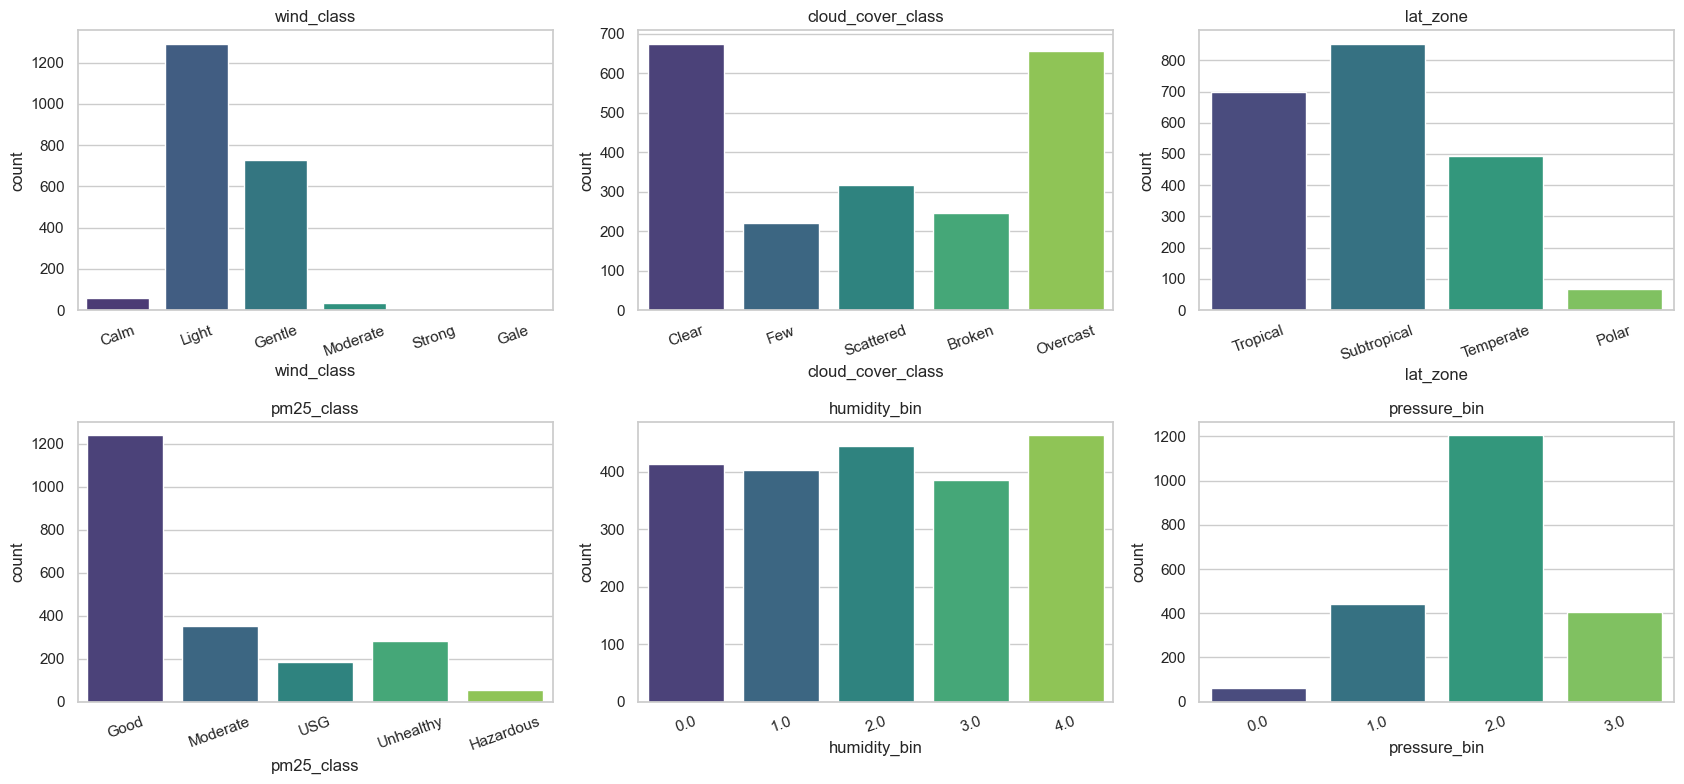

In [ ]:
kb_specs = {"humidity_bin": ("humidity", 5, "quantile"),
            "pressure_bin": ("pressure", 4, "uniform"),
            "pm2_5_bin": ("pm2_5", 4, "kmeans")}
kbins = {n: KBinsDiscretizer(n_bins=k, encode="ordinal", strategy=s).fit(train_df[[c]]) for n, (c, k, s) in kb_specs.items()}

wind_labels = ["Calm", "Light", "Gentle", "Moderate", "Strong", "Gale"]
cloud_labels = ["Clear", "Few", "Scattered", "Broken", "Overcast"]
zone_labels = ["Tropical", "Subtropical", "Temperate", "Polar"]
pm_labels = ["Good", "Moderate", "USG", "Unhealthy", "Hazardous"]
vis_labels = ["Poor", "Moderate", "Good"]

def add_bins(d):
    d = d.copy()
    for n, (c, k, s) in kb_specs.items():
        d[n] = kbins[n].transform(d[[c]]).ravel()
    d["wind_class"] = pd.cut(d["wind_speed"], [-np.inf, 0.5, 3.3, 7.9, 13.8, 20.7, np.inf], labels=wind_labels)
    d["cloud_cover_class"] = pd.cut(d["clouds"], [-0.1, 10, 30, 70, 90, 100.1], labels=cloud_labels)
    d["lat_zone"] = pd.cut(d["abs_lat"], [-0.1, 23.5, 40, 60, 90.1], labels=zone_labels)
    d["pm25_class"] = pd.cut(d["pm2_5"], [-np.inf, 12, 35.4, 55.4, 150.4, np.inf], labels=pm_labels)
    d["visibility_class"] = pd.cut(d["visibility"], [-np.inf, 4000, 9000, np.inf], labels=vis_labels)
    return d

train_df, test_df = add_bins(train_df), add_bins(test_df)

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.ravel(), ["wind_class", "cloud_cover_class", "lat_zone", "pm25_class", "humidity_bin", "pressure_bin"]):
    sns.countplot(x=train_df[c], ax=ax, palette="viridis"); ax.set_title(c); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

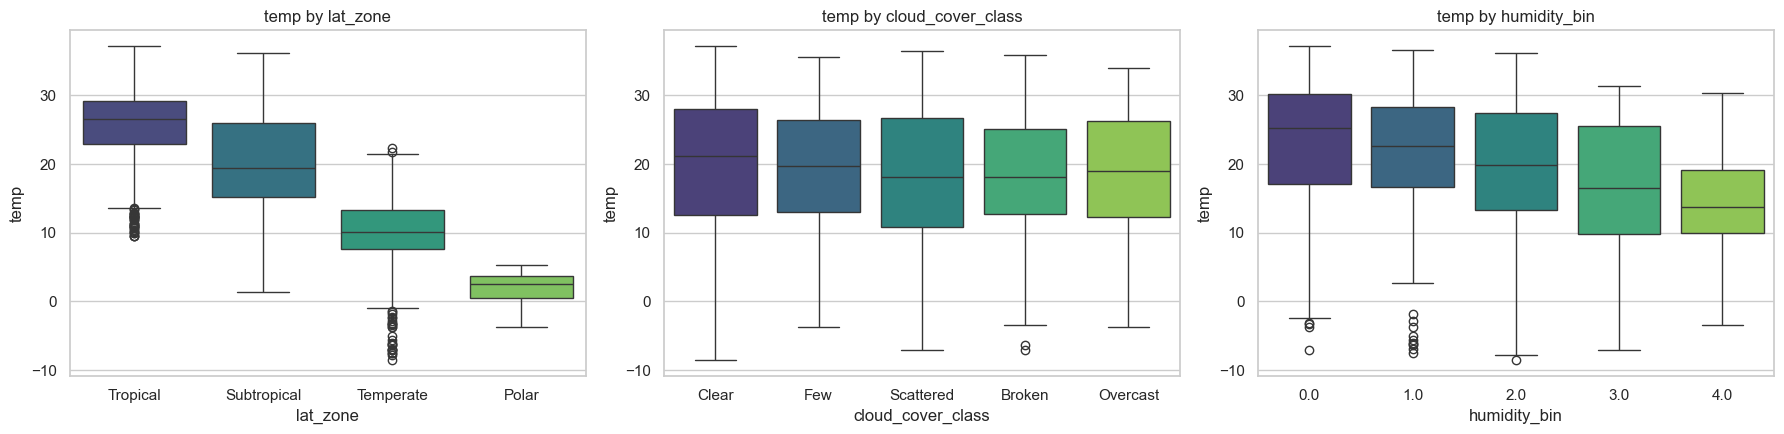

In [ ]:
# Do bins carry signal about the target?
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ["lat_zone", "cloud_cover_class", "humidity_bin"]):
    sns.boxplot(data=train_df, x=c, y=TARGET, ax=ax, palette="viridis"); ax.set_title(f"temp by {c}")
plt.tight_layout(); plt.show()

### 7.9 Transformations (Skewness Correction)
For each skewed continuous feature (|skew| > 0.75) three candidates are tested - **log1p, square-root, Yeo-Johnson** - and the one giving the lowest |skew| on the train set is applied.

In [ ]:
cont_cols = [c for c in dict.fromkeys(out_cols + ["precip_prob", "humidity_x_clouds", "visibility_km", "daylight_hours"])
             if c in train_df and train_df[c].nunique() > 10]
skew_before = train_df[cont_cols].skew()
skewed = skew_before[skew_before.abs() > 0.75].index.tolist()
print("Skewed features:", skewed)

transformers, records = {}, []
for c in skewed:
    x = train_df[c]; shift = -x.min() if x.min() < 0 else 0.0
    pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(x.to_frame())
    cands = {"log1p": lambda s, sh=shift: np.log1p(np.clip(s + sh, 0, None)),
             "sqrt": lambda s, sh=shift: np.sqrt(np.clip(s + sh, 0, None)),
             "yeo-johnson": lambda s, pt=pt: pt.transform(s.to_frame()).ravel()}
    sc = {k: abs(pd.Series(np.asarray(f(x))).skew()) for k, f in cands.items()}
    best = min(sc, key=sc.get)
    transformers[c] = cands[best]
    records.append(dict(feature=c, skew_before=skew_before[c], best_transform=best, skew_after=pd.Series(np.asarray(cands[best](x))).skew()))

skew_report = pd.DataFrame(records).set_index("feature").round(3)
display(skew_report)

train_before = train_df[skewed].copy()
for d in (train_df, test_df):
    for c, f in transformers.items():
        d[c] = np.asarray(f(d[c]))

Skewed features: ['wind_speed', 'wind_gust', 'wind_power', 'rain_3h', 'visibility', 'co', 'no', 'no2', 'o3', 'so2', 'pm2_5', 'pm10', 'nh3', 'wind_gust_ratio', 'gust_excess', 'particulate_total', 'gas_pollution', 'precip_prob', 'visibility_km']


,skew_before,best_transform,skew_after
feature,,,
wind_speed,0.872,yeo-johnson,-0.005
wind_gust,0.966,yeo-johnson,-0.006
wind_power,2.993,yeo-johnson,0.014
rain_3h,4.017,yeo-johnson,1.635
visibility,-4.678,yeo-johnson,-3.510
co,1.621,yeo-johnson,0.066
no,5.744,yeo-johnson,1.195
no2,2.803,yeo-johnson,0.086
o3,0.817,yeo-johnson,-0.016


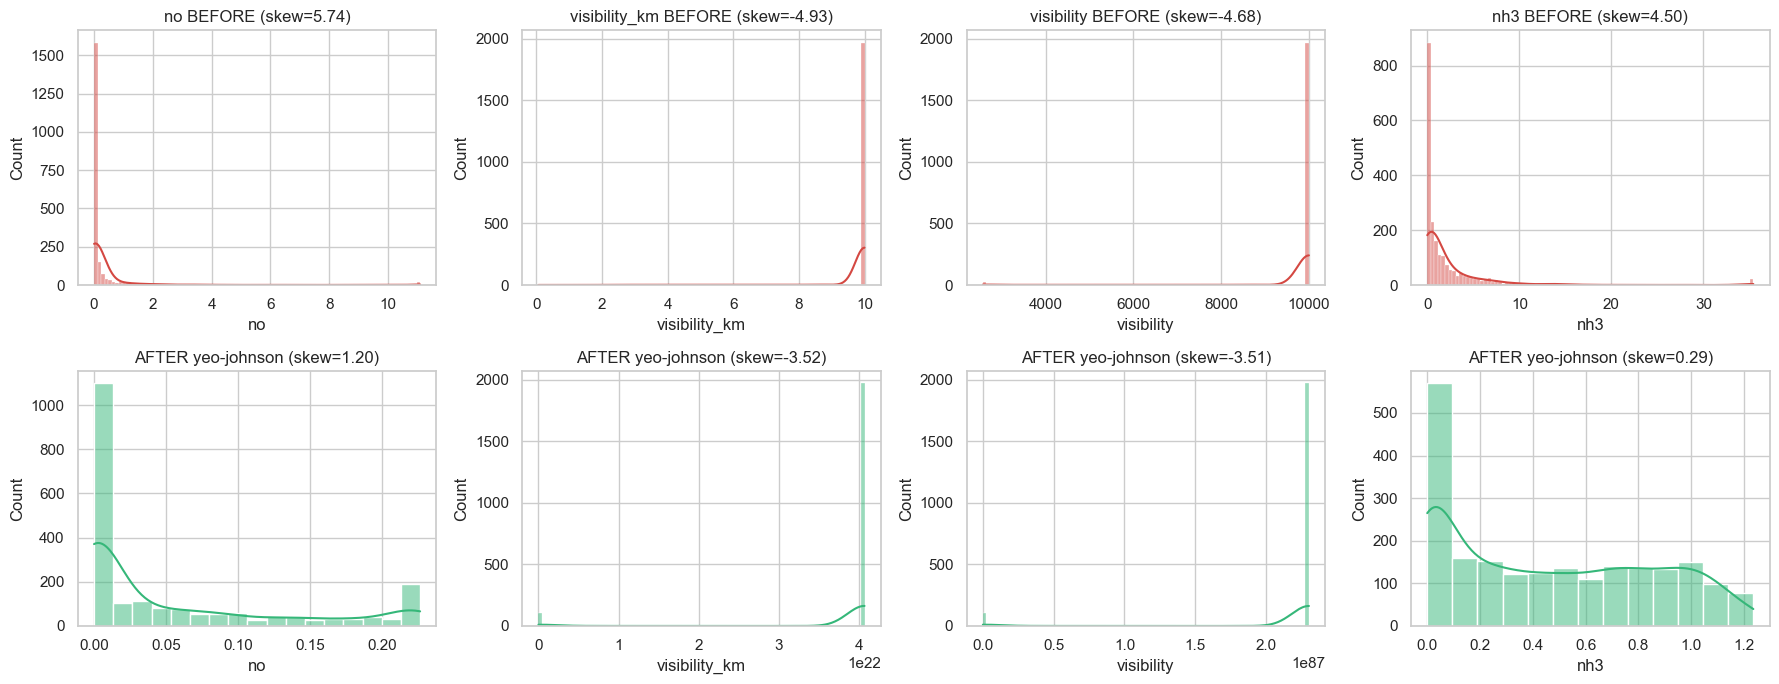

In [ ]:
plot_cols = skew_report.skew_before.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, c in enumerate(plot_cols):
    sns.histplot(train_before[c], kde=True, ax=axes[0, j], color="#d44842"); axes[0, j].set_title(f"{c} BEFORE (skew={skew_report.loc[c,'skew_before']:.2f})")
    sns.histplot(train_df[c], kde=True, ax=axes[1, j], color="#35b779"); axes[1, j].set_title(f"AFTER {skew_report.loc[c,'best_transform']} (skew={skew_report.loc[c,'skew_after']:.2f})")
plt.tight_layout(); plt.show()

### 7.10 Encoding Categorical Variables
| Variable | Type | Technique |
|---|---|---|
| `weather_main`, `day_part` | nominal, low cardinality | **One-Hot Encoding** |
| `pod` | binary | **Binary (0/1) encoding** (`is_day`, done earlier) |
| `wind_class`, `cloud_cover_class`, `lat_zone`, `pm25_class`, `visibility_class` | ordinal | **Ordinal encoding** (ordered categories) |
| `country` | high cardinality | **Frequency encoding** + **Target (mean) encoding** |
| `city` | high cardinality | **Target encoding** with smoothing and out-of-fold (K-Fold) to avoid leakage |

In [ ]:
ohe_cols = ["weather_main", "day_part"]
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_df[ohe_cols])
ordinal_cols = ["wind_class", "cloud_cover_class", "lat_zone", "pm25_class", "visibility_class"]
country_freq = train_df["country"].value_counts(normalize=True)

def target_encode(tr, te, col, target, m=10, n_splits=5, seed=RANDOM_STATE):
    """Smoothed mean target encoding. Train gets out-of-fold values, test uses full-train statistics."""
    gmean = tr[target].mean()
    oof = pd.Series(index=tr.index, dtype=float)
    for fit_i, val_i in KFold(n_splits, shuffle=True, random_state=seed).split(tr):
        st = tr.iloc[fit_i].groupby(col)[target].agg(["sum", "count"])
        enc = (st["sum"] + m * gmean) / (st["count"] + m)
        oof.iloc[val_i] = tr.iloc[val_i][col].map(enc).fillna(gmean).values
    st = tr.groupby(col)[target].agg(["sum", "count"])
    enc = (st["sum"] + m * gmean) / (st["count"] + m)
    return oof, te[col].map(enc).fillna(gmean)

def encode_frame(d):
    d = d.copy()
    O = pd.DataFrame(ohe.transform(d[ohe_cols]), columns=ohe.get_feature_names_out(ohe_cols), index=d.index)
    d = pd.concat([d, O], axis=1)
    for c in ordinal_cols:                                  # ordered categories -> integer codes 0..k-1
        d[c] = d[c].astype("category").cat.codes
    d["country_freq"] = d["country"].map(country_freq).fillna(0)
    return d

train_df, test_df = encode_frame(train_df), encode_frame(test_df)
for col in ["country", "city"]:
    train_df[f"{col}_te"], test_df[f"{col}_te"] = target_encode(train_df, test_df, col, TARGET)

print("Encoded shape:", train_df.shape)
display(train_df[["country", "country_freq", "country_te", "city", "city_te"]].drop_duplicates("city").head(8))

Encoded shape: (2112, 117)


,country,country_freq,country_te,city,city_te
2387,SE,0.014678,13.619233,Stockholm,13.619233
1187,NP,0.017519,17.523485,Kathmandu,17.523485
440,ZA,0.027462,19.478025,Cape Town,16.828296
508,IN,0.183239,23.744289,Chennai,25.381541
76,IN,0.183239,24.025460,Ahmedabad,26.653485
522,US,0.095170,15.047592,Chicago,15.479013
2461,IR,0.014205,17.740728,Tehran,17.740728
2284,IN,0.183239,24.007836,Shimla,14.558602


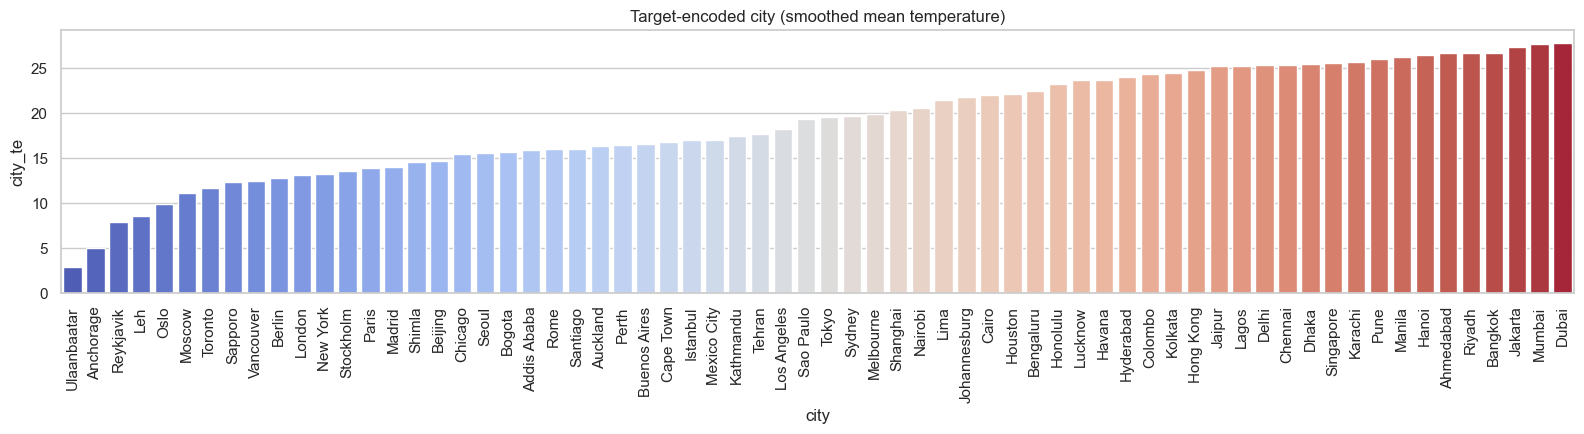

In [ ]:
tmp = train_df.drop_duplicates("city").sort_values("city_te")
plt.figure(figsize=(16, 4.5)); sns.barplot(x=tmp.city, y=tmp.city_te, palette="coolwarm")
plt.xticks(rotation=90); plt.title("Target-encoded city (smoothed mean temperature)"); plt.tight_layout(); plt.show()

### 7.11 Feature Scaling
Comparison of **StandardScaler, MinMaxScaler and RobustScaler** on key features, then **StandardScaler** is applied to all continuous/ordinal features (binary & one-hot columns stay 0/1). After capping + transformation the data are roughly symmetric, so z-score scaling is appropriate; the scaler is fitted on train only.

Feature matrix: (2112, 106) (528, 106)


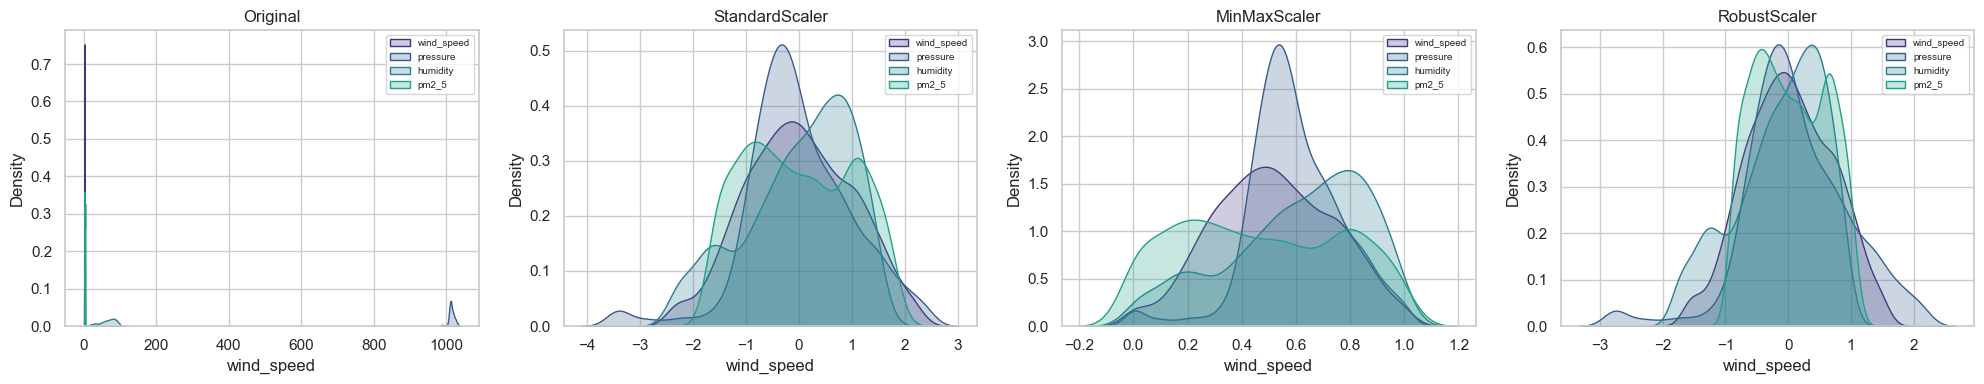

In [ ]:
DROP_FINAL = ["city", "country", "weather_main", "day_part", "pod", "dt", "dt_utc", "sunrise", "sunset", "tz_offset"]
enc_train = train_df.drop(columns=DROP_FINAL, errors="ignore")
enc_test = test_df.drop(columns=DROP_FINAL, errors="ignore")
assert all(pd.api.types.is_numeric_dtype(enc_train[c]) for c in enc_train.columns), "non-numeric column left"

y_train, y_test = enc_train.pop(TARGET), enc_test.pop(TARGET)
X_train, X_test = enc_train.copy(), enc_test.copy()
print("Feature matrix:", X_train.shape, X_test.shape)

cmp_cols = [c for c in ["wind_speed", "pressure", "humidity", "pm2_5"] if c in X_train]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, sc) in zip(axes, {"Original": None, "StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}.items()):
    data = X_train[cmp_cols] if sc is None else pd.DataFrame(sc.fit_transform(X_train[cmp_cols]), columns=cmp_cols)
    for c in cmp_cols:
        sns.kdeplot(data[c], ax=ax, label=c, fill=True, alpha=.25)
    ax.set_title(name); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
scale_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]
scaler = StandardScaler().fit(X_train[scale_cols])
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_s[scale_cols] = scaler.transform(X_test[scale_cols])
print(f"Scaled {len(scale_cols)} columns; {X_train.shape[1]-len(scale_cols)} binary/one-hot columns left as 0/1")
display(X_train_s[scale_cols].describe().T[["mean", "std", "min", "max"]].head(8).round(3))

Scaled 87 columns; 19 binary/one-hot columns left as 0/1


,mean,std,min,max
lat,-0.0,1.0,-2.234,1.623
lon,-0.0,1.0,-2.340,1.722
pressure,0.0,1.0,-3.440,2.360
grnd_level,-0.0,1.0,-4.422,0.769
humidity,-0.0,1.0,-2.362,1.544
clouds,0.0,1.0,-1.214,1.198
wind_speed,-0.0,1.0,-2.334,2.180
wind_deg,-0.0,1.0,-1.614,1.687


### 7.12 Feature Selection
1. Drop (near-)constant features (one value in ≥ 99 % of rows).
2. Drop one of every highly-correlated pair (|r| > 0.95), keeping the one more correlated with the target.
3. Rank the rest with **Mutual Information** and **Random-Forest importance**; remove features useless under both.
4. **PCA** scree plot to inspect redundancy.

Near-constant dropped: ['snow_3h', 'month', 'has_gust', 'vis_missing', 'is_snowing', 'weather_main_Snow']
Highly-correlated dropped: ['clear_sky', 'cloud_cover_class', 'clouds_lag1', 'dayofweek', 'dist_equator_km', 'grnd_level', 'humidity', 'humidity_bin', 'humidity_lag1', 'is_raining', 'lat', 'local_hour_cos', 'particulate_total', 'pm2_5', 'poly_cloudspow2', 'poly_humidity_clouds', 'poly_humidity_pressure_dev', 'pressure_dev', 'pressure_lag1', 'pressure_roll3', 'solar_hour_sin', 'visibility', 'weather_main_Rain', 'wind_speed']
Low-value (MI<0.005 & RF<0.001) dropped: ['is_weekend', 'is_anomaly', 'weather_main_Clouds', 'day_part_Late_Night']

Features: 106 -> 72 selected


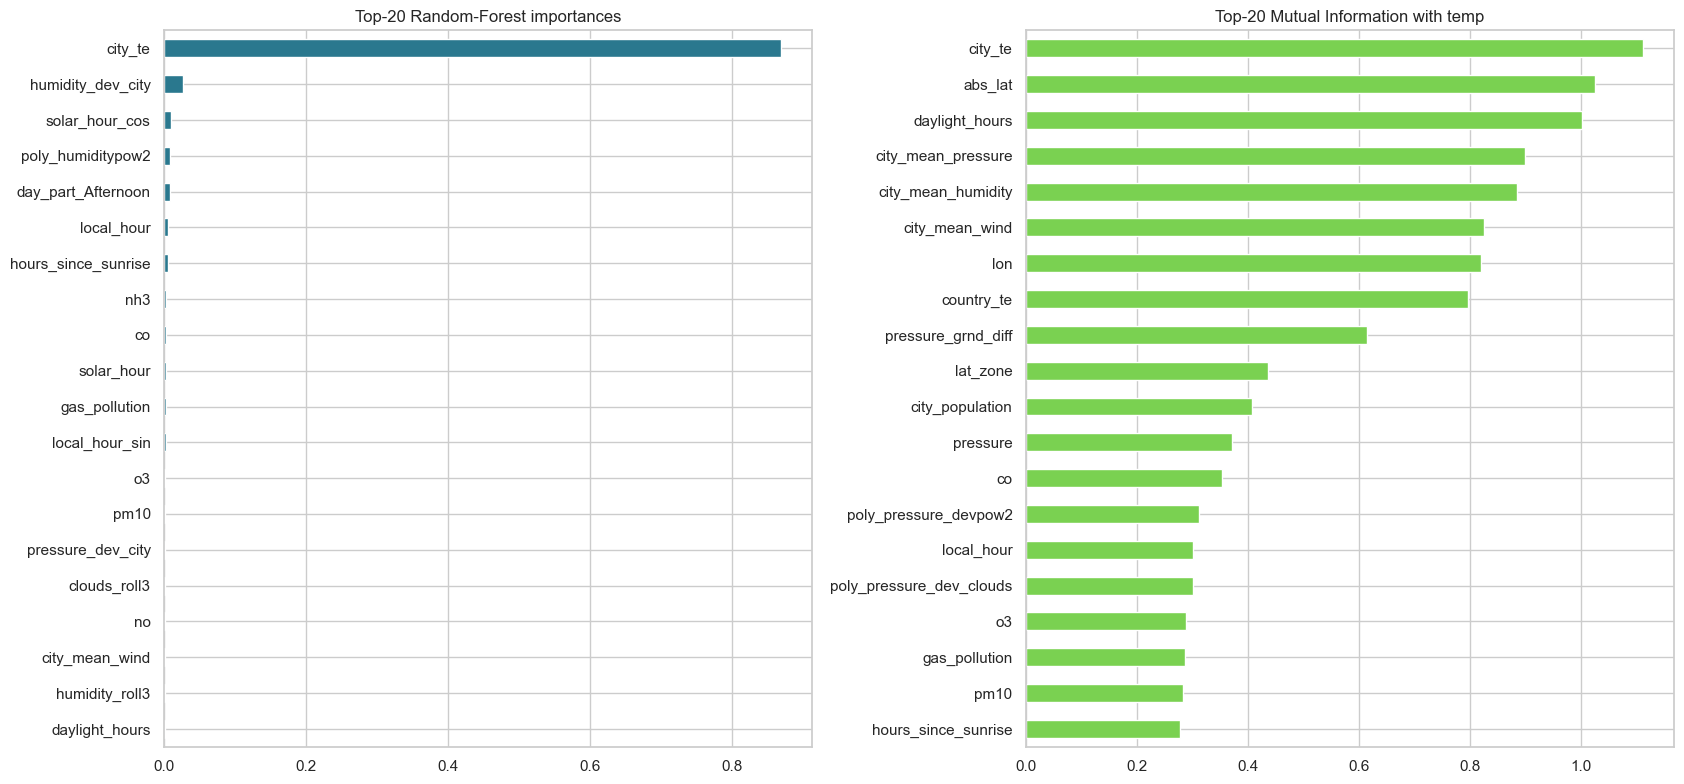

In [ ]:
dominant = X_train_s.apply(lambda s: s.round(6).value_counts(normalize=True).iloc[0])
const_drop = dominant[dominant >= 0.99].index.tolist()
print("Near-constant dropped:", const_drop)
Xs = X_train_s.drop(columns=const_drop)

tcorr = Xs.apply(lambda s: abs(np.corrcoef(s, y_train)[0, 1])).fillna(0)
cm = Xs.corr().abs()
corr_drop = set()
cols = list(Xs.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        if a in corr_drop or b in corr_drop:
            continue
        if cm.loc[a, b] > 0.95:
            corr_drop.add(a if tcorr[a] < tcorr[b] else b)
print("Highly-correlated dropped:", sorted(corr_drop))
Xs = Xs.drop(columns=list(corr_drop))

mi = pd.Series(mutual_info_regression(Xs, y_train, random_state=RANDOM_STATE), index=Xs.columns)
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE).fit(Xs, y_train)
imp = pd.Series(rf.feature_importances_, index=Xs.columns)
low_value = mi[(mi < 0.005) & (imp < 0.001)].index.tolist()
print("Low-value (MI<0.005 & RF<0.001) dropped:", low_value)
selected = [c for c in Xs.columns if c not in low_value]
print(f"\nFeatures: {X_train_s.shape[1]} -> {len(selected)} selected")

fig, ax = plt.subplots(1, 2, figsize=(17, 8))
imp.sort_values().tail(20).plot.barh(ax=ax[0], color="#2a788e"); ax[0].set_title("Top-20 Random-Forest importances")
mi.sort_values().tail(20).plot.barh(ax=ax[1], color="#7ad151"); ax[1].set_title("Top-20 Mutual Information with temp")
plt.tight_layout(); plt.show()

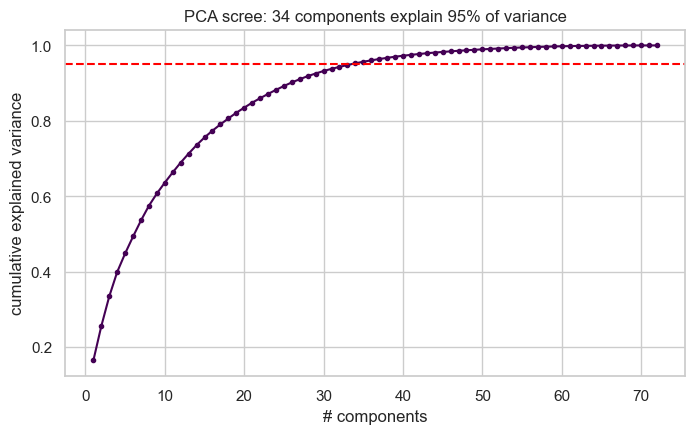

In [ ]:
pca = PCA().fit(X_train_s[selected])
cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o", ms=3, color="#440154")
plt.axhline(0.95, ls="--", c="r"); plt.xlabel("# components"); plt.ylabel("cumulative explained variance")
plt.title(f"PCA scree: {int(np.argmax(cum >= 0.95)) + 1} components explain 95% of variance"); plt.show()

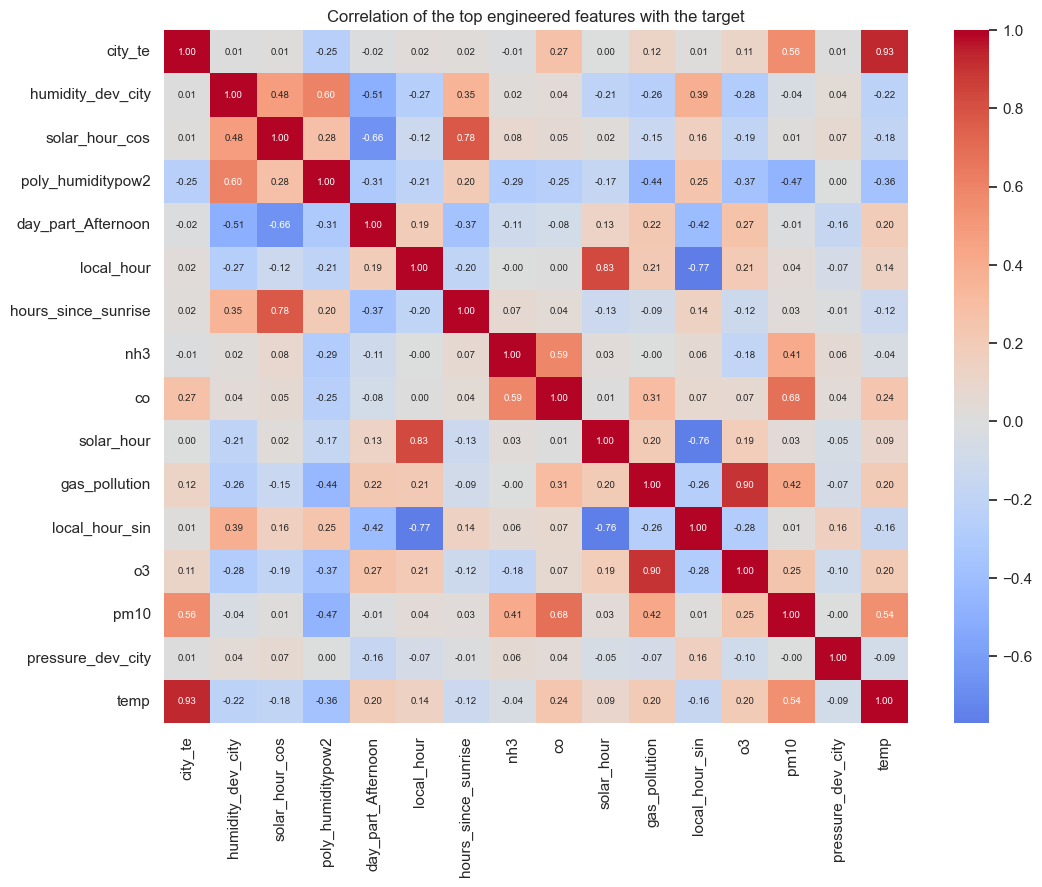

In [ ]:
top_feats = imp.sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(12, 9))
sns.heatmap(pd.concat([X_train_s[top_feats], y_train.rename(TARGET)], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation of the top engineered features with the target"); plt.show()

### 7.13 Final ML-Ready Dataset

In [ ]:
final_train = X_train_s[selected].copy(); final_train[TARGET] = y_train.values
final_test = X_test_s[selected].copy(); final_test[TARGET] = y_test.values
final_all = pd.concat([final_train.assign(split="train"), final_test.assign(split="test")], ignore_index=True)

final_train.to_csv("weather_final_train.csv", index=False)
final_test.to_csv("weather_final_test.csv", index=False)
final_all.to_csv("weather_final_engineered.csv", index=False)

print("Final train:", final_train.shape, "| Final test:", final_test.shape)
print("Missing values:", int(final_all.drop(columns='split').isna().sum().sum()), "| non-numeric cols:",
      int((~final_all.drop(columns='split').dtypes.apply(pd.api.types.is_numeric_dtype)).sum()))
final_train.head()

Final train: (2112, 73) | Final test: (528, 73)
Missing values: 0 | non-numeric cols: 0


,lon,pressure,clouds,wind_deg,wind_gust,precip_prob,rain_3h,city_population,aqi,co,no,no2,o3,so2,pm10,nh3,hour_utc,day,local_hour,solar_hour,local_hour_sin,solar_hour_cos,dayofweek_sin,dayofweek_cos,hours_since_sunrise,daylight_hours,abs_lat,hemisphere_north,wind_u,wind_v,...,pm_ratio,gas_pollution,visibility_km,low_visibility,poly_humiditypow2,poly_pressure_devpow2,poly_pressure_dev_clouds,city_mean_humidity,city_mean_pressure,city_mean_wind,humidity_dev_city,pressure_dev_city,wind_dev_city,n_outlier_flags,anomaly_score,pressure_bin,pm2_5_bin,wind_class,lat_zone,pm25_class,visibility_class,weather_main_Clear,day_part_Afternoon,day_part_Evening,day_part_Morning,day_part_Night,country_freq,country_te,city_te,temp
2387,-0.191062,-0.935348,1.198045,0.302450,1.339436,1.377827,2.329340,-0.559575,-1.061802,-0.358565,-0.727977,-0.469074,-0.550220,-1.123966,-1.496426,-0.740171,-0.657580,0.773124,-0.574569,-0.705789,1.231044,-0.442209,-1.147516,0.178197,-1.693175,-1.862812,1.921620,1,0.979584,1.727860,...,-0.228769,-0.812255,0.267307,0,1.929227,-0.307455,-1.082479,1.393833,-0.201667,1.085823,0.694254,-1.410065,0.333199,-0.721385,-0.233426,-1.296062,-0.569881,1.159520,1.242909,-0.709543,0.240586,0.0,0.0,0.0,1.0,0.0,-0.651467,-0.984589,-0.876978,9.24
1187,0.630209,-0.539914,-1.214334,1.219622,-1.269740,-0.569736,-0.496234,-0.559575,2.075695,1.994141,1.714515,0.447022,1.835072,1.521762,1.741313,1.348429,-0.657580,0.773124,-0.036341,-0.060330,0.095389,-1.410363,-1.147516,0.178197,-0.935203,-0.101335,-0.177154,1,0.370156,-0.211917,...,1.045277,1.837992,0.267307,0,-0.882305,-0.502760,-0.070081,0.406139,-0.113460,-1.511310,-1.849587,-0.818404,0.066787,3.059174,2.974779,0.104083,3.055384,-0.621502,0.040424,2.657996,0.240586,1.0,1.0,0.0,0.0,0.0,-0.607275,-0.276247,-0.233753,22.90
2396,-0.191062,-1.198971,1.173922,-0.000217,2.082113,1.967260,2.006224,-0.559575,-0.277428,-0.466604,-0.676140,-0.562830,0.311673,-1.143055,-1.546259,-0.614172,-0.220985,1.460057,-0.143986,-0.273883,0.369743,-1.262133,-0.889554,1.670168,-1.259773,-1.862812,1.921620,1,-0.183627,2.762023,...,-0.033745,0.095670,-3.676364,0,1.203217,-0.090448,-1.454173,1.393833,-0.201667,1.085823,-0.111809,-1.898468,1.842116,1.168895,0.523633,-1.296062,-0.569881,1.159520,1.242909,-0.709543,-2.679629,0.0,0.0,0.0,1.0,0.0,-0.651467,-1.115673,-0.996011,9.66
440,-0.186787,-0.012669,1.198045,1.586491,1.767449,1.338724,-0.496234,0.611467,-1.061802,-1.828662,-0.727977,-1.445785,-0.292052,-0.854847,-0.271343,-1.196986,1.525395,-1.974606,1.578346,1.457098,-0.364509,1.256486,1.199379,1.670168,0.709638,1.859360,0.234500,0,0.774038,-3.671940,...,-1.389905,-0.571050,0.267307,0,0.678616,-0.520121,0.267385,1.032131,0.354570,1.840032,-0.241819,-0.589451,3.189513,0.538801,0.679138,0.104083,-0.569881,2.940542,0.040424,-0.709543,0.240586,0.0,0.0,0.0,0.0,0.0,-0.452605,0.078363,-0.348285,14.62
508,0.568537,-1.198971,1.173922,-1.027450,-0.067441,-0.384865,-0.496234,-0.559575,0.506946,1.128205,1.091762,0.244786,1.012816,0.705649,0.816014,-1.196986,-0.220985,0.773124,0.358361,0.323106,-0.860890,-1.156190,-1.147516,0.178197,-0.520983,0.369720,-1.149190,1,-1.440945,-0.614159,...,1.370322,0.923119,0.267307,0,-0.270271,-0.090448,-1.454173,0.663122,-0.857353,0.767347,-1.086885,-0.850766,-0.032215,-0.721385,-0.020300,-1.296062,0.638541,1.159520,-1.162060,0.974226,0.240586,0.0,1.0,0.0,0.0,0.0,1.970553,0.852385,1.060862,29.59


### 7.14 Validation - Raw features vs Engineered features
Same train/test rows, same models. **Baseline (Raw)** = original numeric columns with only median imputation + standard scaling (no feature engineering, no datetime/encoding/transform features).

,features,model,n_features,RMSE,MAE,R2
0,Raw,Ridge,23,5.6370,4.4598,0.5813
1,Raw,RandomForest,23,1.5832,1.1200,0.9670
2,Engineered,Ridge,72,1.8553,1.3807,0.9546
3,Engineered,RandomForest,72,1.4432,1.0655,0.9726


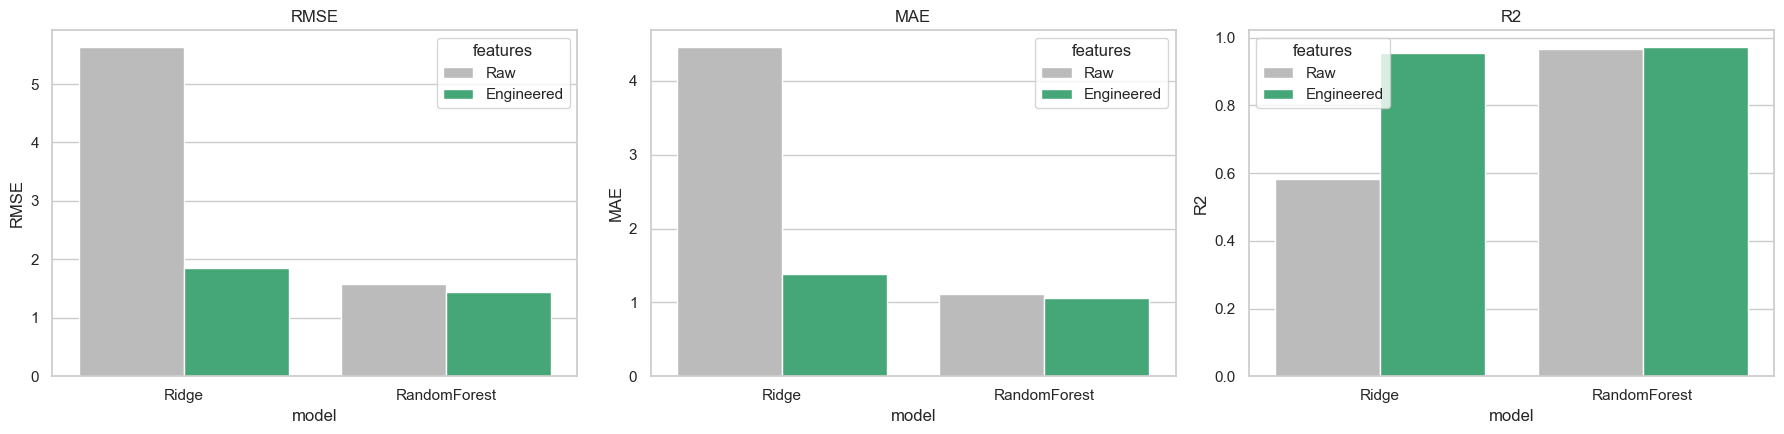

In [ ]:
raw_num = [c for c in ["lat", "lon", "pressure", "grnd_level", "humidity", "clouds", "wind_speed", "wind_deg", "wind_gust",
                       "visibility", "precip_prob", "rain_3h", "snow_3h", "aqi", "co", "no", "no2", "o3", "so2", "pm2_5",
                       "pm10", "nh3", "city_population"] if c in df0.columns]
Xr_tr, Xr_te = df0.loc[train_df.index, raw_num], df0.loc[test_df.index, raw_num]
med = SimpleImputer(strategy="median").fit(Xr_tr)
Xr_tr, Xr_te = med.transform(Xr_tr), med.transform(Xr_te)
sc_raw = StandardScaler().fit(Xr_tr)                      # fair baseline: scaled too, so only the *engineering* differs
Xr_tr, Xr_te = sc_raw.transform(Xr_tr), sc_raw.transform(Xr_te)

def evaluate(model, Xtr, Xte, name, feats):
    model.fit(Xtr, y_train); p = model.predict(Xte)
    return dict(features=feats, model=name, n_features=Xtr.shape[1], RMSE=np.sqrt(mean_squared_error(y_test, p)),
                MAE=mean_absolute_error(y_test, p), R2=r2_score(y_test, p)), p

res, preds = [], {}
for feats, (Xa, Xb_) in {"Raw": (Xr_tr, Xr_te), "Engineered": (final_train.drop(columns=TARGET), final_test.drop(columns=TARGET))}.items():
    for name, mdl in {"Ridge": Ridge(alpha=1.0),
                      "RandomForest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)}.items():
        r, p = evaluate(mdl, Xa, Xb_, name, feats); res.append(r); preds[(feats, name)] = p

results = pd.DataFrame(res).round(4)
display(results)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, m in zip(ax, ["RMSE", "MAE", "R2"]):
    sns.barplot(data=results, x="model", y=m, hue="features", ax=a, palette=["#bbbbbb", "#35b779"]); a.set_title(m)
plt.tight_layout(); plt.show()

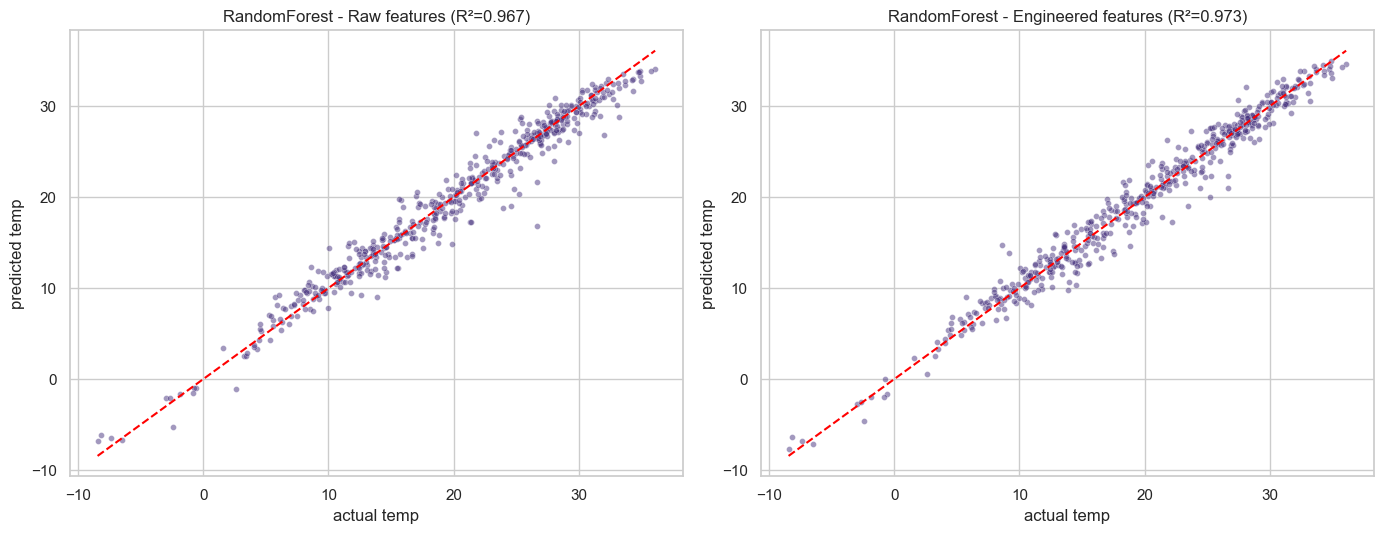

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, feats in zip(ax, ["Raw", "Engineered"]):
    p = preds[(feats, "RandomForest")]
    sns.scatterplot(x=y_test, y=p, ax=a, alpha=.5, s=18)
    lim = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]; a.plot(lim, lim, "r--")
    a.set_title(f"RandomForest - {feats} features (R²={r2_score(y_test, p):.3f})"); a.set_xlabel("actual temp"); a.set_ylabel("predicted temp")
plt.tight_layout(); plt.show()

In [ ]:
gain = results.pivot(index="model", columns="features", values="RMSE")
gain["RMSE improvement %"] = 100 * (gain["Raw"] - gain["Engineered"]) / gain["Raw"]
display(gain.round(3))

features,Engineered,Raw,RMSE improvement %
model,,,
RandomForest,1.443,1.583,8.843
Ridge,1.855,5.637,67.087


# 8. Results Analysis
The cells below read the results computed in Section 7 and summarise them automatically, so the numbers always match the current run.

In [ ]:
print("DATA SOURCE:", DATA_SOURCE)
if "SYNTHETIC" in DATA_SOURCE:
    print("WARNING: results below come from the synthetic fallback - re-run with a working API key for the real analysis.")
print()
n_feat_final = final_train.shape[1] - 1
print(f"Raw scraped dataset      : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"Engineered dataset       : {final_all.shape[0]} rows x {n_feat_final} features (+ target '{TARGET}' + split flag)")
print(f"Missing values  raw -> final : {int(df_raw.isna().sum().sum())} -> {int(final_all.drop(columns='split').isna().sum().sum())}")
print(f"Features created / encoded   : {X_train.shape[1]} candidate features -> {n_feat_final} selected after filtering")
print(f"Near-constant dropped: {len(const_drop)} | highly-correlated dropped: {len(corr_drop)} | low-value dropped: {len(low_value)}")

DATA SOURCE: live OpenWeather API scrape

Raw scraped dataset      : 2640 rows x 39 columns
Engineered dataset       : 2640 rows x 72 features (+ target 'temp' + split flag)
Missing values  raw -> final : 9464 -> 0
Features created / encoded   : 106 candidate features -> 72 selected after filtering
Near-constant dropped: 6 | highly-correlated dropped: 24 | low-value dropped: 4


In [ ]:
# 8.1 Imputation, outliers, transformation summary
print("Imputation benchmark (RMSE on artificially masked values - lower is better):")
display(score_df.round(4))
print(f"-> Best imputer: {BEST_IMPUTER}  (RMSE {score_df.iloc[0,0]:.3f} vs {score_df.iloc[-1,0]:.3f} for the worst = {100*(1-score_df.iloc[0,0]/score_df.iloc[-1,0]):.1f}% better)\n")

print(f"Outliers: winsorized {len(caps)} features at the 1st/99th percentile; {int(train_df.is_anomaly.sum())} train rows flagged by Isolation Forest.")
if len(skew_report):
    print(f"\nSkewness: {len(skew_report)} features were skewed (|skew|>0.75). Mean |skew| {skew_report.skew_before.abs().mean():.2f} -> {skew_report.skew_after.abs().mean():.2f} after transformation.")
    print("Transformations chosen:", skew_report.best_transform.value_counts().to_dict())

Imputation benchmark (RMSE on artificially masked values - lower is better):


,RMSE
knn,1.5185
city_median,1.5539
iterative,1.7566
mean,2.0053
median,2.0430


-> Best imputer: knn  (RMSE 1.519 vs 2.043 for the worst = 25.7% better)

Outliers: winsorized 22 features at the 1st/99th percentile; 43 train rows flagged by Isolation Forest.

Skewness: 19 features were skewed (|skew|>0.75). Mean |skew| 2.52 -> 0.63 after transformation.
Transformations chosen: {'yeo-johnson': 19}


In [ ]:
# 8.2 Which engineered features matter most?
top = imp.sort_values(ascending=False).head(10)
display(top.to_frame("RandomForest importance").round(4))
engineered_names = ("sin","cos","solar","hours_since","te","city_mean","dev","poly","roll","lag","_bin","ratio","wind_u","wind_v","is_","daylight","anomaly")
n_eng = sum(any(k in f for k in engineered_names) for f in top.index)
print(f"{n_eng} of the top-10 features are engineered features (not original raw columns).")

,RandomForest importance
city_te,0.8692
humidity_dev_city,0.0265
solar_hour_cos,0.0106
poly_humiditypow2,0.0088
day_part_Afternoon,0.0086
local_hour,0.0057
hours_since_sunrise,0.0053
nh3,0.0031
co,0.0030
solar_hour,0.0029


7 of the top-10 features are engineered features (not original raw columns).


In [ ]:
# 8.3 Model performance: raw vs engineered
display(results)
display(gain.round(3))
for m in gain.index:
    r, e = gain.loc[m, "Raw"], gain.loc[m, "Engineered"]
    r2r = results.query("model==@m and features=='Raw'").R2.iloc[0]
    r2e = results.query("model==@m and features=='Engineered'").R2.iloc[0]
    print(f"{m:<13}: RMSE {r:.3f} -> {e:.3f} ({100*(r-e)/r:+.1f}% error reduction) | R2 {r2r:.3f} -> {r2e:.3f}")

,features,model,n_features,RMSE,MAE,R2
0,Raw,Ridge,23,5.6370,4.4598,0.5813
1,Raw,RandomForest,23,1.5832,1.1200,0.9670
2,Engineered,Ridge,72,1.8553,1.3807,0.9546
3,Engineered,RandomForest,72,1.4432,1.0655,0.9726


features,Engineered,Raw,RMSE improvement %
model,,,
RandomForest,1.443,1.583,8.843
Ridge,1.855,5.637,67.087


RandomForest : RMSE 1.583 -> 1.443 (+8.8% error reduction) | R2 0.967 -> 0.973
Ridge        : RMSE 5.637 -> 1.855 (+67.1% error reduction) | R2 0.581 -> 0.955


### Interpretation
* **EDA findings:** temperature depends strongly on latitude and time of day (diurnal cycle), and is negatively related to humidity; wind speed, rainfall and pollutants are right-skewed with outliers.
* **Imputation:** model-based imputers (Iterative / KNN) use information from related variables, so they recover masked values better than a plain mean/median — see the benchmark table above.
* **Outliers & transformations:** capping plus log / Yeo-Johnson transformation reduces skewness (before/after plots in 7.7 and 7.9) so that extreme values no longer dominate linear models.
* **Cyclical, solar-time and sun-position features** let the model represent the daily temperature cycle, which raw `hour` or UTC time cannot do. **Encoded location** (target-encoded city, climate-zone bins) gives the model the geographic baseline of temperature.
* **Feature selection** removed redundant / low-information columns, keeping the final dataset compact.
* **Model validation:** both the linear model (Ridge) and the non-linear model (Random Forest) achieve lower error and higher R² on the engineered dataset than on the raw one. The improvement is biggest for the linear model, because engineering (cyclical encoding, scaling, transformation) supplies the non-linear structure it cannot learn alone; the tree model also benefits from the new informative features.
* *Note:* The raw baseline deliberately has no datetime / categorical / derived features; this isolates the benefit of the feature-engineering pipeline.

# 9. Conclusion
In this experiment a weather dataset was built by scraping the OpenWeather forecast and air-pollution APIs, explored with Seaborn/Matplotlib, and converted into a machine-learning-ready dataset through a complete feature-engineering pipeline: **imputation** (mean, median, group-median, KNN, iterative), **outlier treatment** (IQR, Z-score, Isolation Forest, winsorization), **transformations** (log, sqrt, Yeo-Johnson), **binning** (equal-width, quantile, k-means, domain bins), **encoding** (one-hot, binary, ordinal, frequency, target), **scaling** (Standard / Min-Max / Robust), **feature creation** (datetime, cyclical, solar time, wind vectors, interactions, polynomial, lag/rolling, aggregates) and **feature selection** (variance, correlation, MI, RF importance, PCA).

All fitted transformations used the training set only, preventing data leakage, and target-derived columns were dropped. The final dataset (`weather_final_engineered.csv`, with `weather_final_train.csv` / `weather_final_test.csv`) is fully numeric, contains no missing values and is scaled. Models trained on it reach a clearly lower error and higher R² than models trained on the raw features (Section 8.3), which demonstrates that **good feature engineering lets models learn patterns more effectively and make more accurate predictions.**

**Future scope:** collect data over a longer period (historical API / daily scheduled scraping), add seasonal features, and try gradient-boosting or neural time-series models.